# Smillie2019
# Standard scanpy workflow version 2.8 #

Changes: 
- Adding leiden clustering as default and a generic cluster function.
- BBKNN is the default batch correction method

### Import section ###

In [1]:
import besca as bc
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy import sparse, io
import os
import time
sc.logging.print_versions()

import logging
import seaborn as sns

# for standard processing, set verbosity to minimum
sc.settings.verbosity = 0  # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(dpi=80)
version = '2.8'
start0 = time.time()

-----
anndata     0.7.5
scanpy      1.6.1
sinfo       0.3.1
-----
PIL                 8.1.0
absl                NA
anndata             0.7.5
annoy               NA
attr                20.3.0
backcall            0.2.0
bbknn               NA
besca               2.4+51.g647a478.dirty
biothings_client    0.2.1
cached_property     1.5.2
certifi             2020.12.05
cffi                1.14.4
chardet             4.0.0
colorama            0.4.4
constants           NA
cycler              0.10.0
cython_runtime      NA
dask                2021.02.0
dateutil            2.8.1
decorator           4.4.2
deprecate           0.3.0
dominate            2.6.0
fbpca               NA
fsspec              2021.06.1
future_fstrings     NA
get_version         2.1
google              NA
h5py                3.1.0
highs_wrapper       NA
idna                2.10
igraph              0.8.3
importlib_metadata  1.7.0
intervaltree        NA
ipykernel           5.4.2
ipython_genutils    0.2.0
ipywidgets          7.6.3

## Setup Standard Wokflow

### Parameters to be set - on the command line or here ###

In [2]:
# decisions to be made
species = 'human'
batch_to_correct = 'Subject' # must be "None" or any one of the labels in "metadata.tsv", ID, SPECIES, TISSUE, DONOR, TREATMENT; typically "ID" or "DONOR"
analysis_name = 'standard_workflow_besca2_0_regress_out_before_hvg_selection'
split_condition='celltype_highlevel' #'experiment' is generally a good default
dynrange=['B2m','Actb','Pgk1','Ctcf'] #genes for which to plot dynamic range
if species=='human': dynrange=[x.upper() for x in dynrange]

#additional labeling
labeling_to_use = 'Cluster' # must be "None" or any one of the labels in "metadata.tsv", ID, SPECIES, TISSUE, DONOR, TREATMENT; typically "ID" or "DONOR"
labeling_name = 'Smillie2019' # define name under which the labeling should be exported
labeling_description = 'celltype annotation from Smillie et al. Intra- and Inter-cellular Rewiring of the Human Colon during Ulcerative Colitis. Cell. 2019' #define description which should be saved to labeling_info file
labeling_author = 'Smillie2019' #define author which shoudl be saved to labeling info file

### Define Input ###

In [3]:
# define filepath (this is the folder that contains "raw" and "analyzed")
#root_path = os.getcwd()
root_path = './'

### Standard parameters - these should be kept as stable as possible ###

In [4]:
# the standard parameter section
standard_min_genes = 800
standard_min_cells = 30
standard_min_counts = 2000
standard_n_genes = 8000 # this is the most tricky one to set
standard_percent_mito = 0.2
standard_max_counts = 100000 #might be redundant with n_genes

## Standard Pipeline
(note nothing below this point should be modified!!)

In [5]:
#define standardized filepaths based on above input
results_folder = os.path.join(root_path, 'analyzed', analysis_name)
results_file = os.path.join(results_folder, analysis_name + '.h5ad') # specify a .h5ad file for storing the results
log_file = os.path.join(results_folder, analysis_name + '.standard.log') # specify a log file for keeping a short summary and overview
sc.settings.figdir = os.path.join(results_folder, 'figures')

#setup standard workflow (generates output directories and setsup logging file)
bc.st.setup(results_folder, 
          analysis_name, 
          labeling_name, 
          labeling_to_use, 
          log_file, 
          version,
          root_path, 
          species, 
          batch_to_correct, 
          standard_min_genes,
          standard_min_cells,
          standard_min_counts,
          standard_n_genes,
          standard_percent_mito,
          standard_max_counts)

#read input data
#adata = bc.st.read_matrix(root_path)
adata = bc.datasets.Smillie2019_raw()

LOG MESSAGE: Standard Pipeline Version 2.8 used
LOG MESSAGE: 2021-07-16
LOG MESSAGE: Analysis 'standard_workflow_besca2_0_regress_out_before_hvg_selection' on data located in'./'
LOG MESSAGE: species: human
LOG MESSAGE: Batch effect to correct: Subject
LOG MESSAGE: Parameters:
LOG MESSAGE: 	standard_min_genes = 800
LOG MESSAGE: 	standard_min_cells = 30
LOG MESSAGE: 	standard_min_counts = 2000
LOG MESSAGE: 	standard_n_genes = 8000
LOG MESSAGE: 	standard_max_counts = 100000
LOG MESSAGE: 	standard_percent_mito = 0.2
LOG MESSAGE: 	Time for creating all output directories and setting up logging: 0.009s


all output directories created successfully


In [6]:
adata

AnnData object with n_obs × n_vars = 365492 × 21784
    obs: 'CELL', 'Cluster', 'Health', 'Location', 'Subject', 'celltype_highlevel', 'nGene', 'nUMI', 'original_name'
    var: 'ENSEMBL', 'SYMBOL'

In [7]:
#calculate mitochondrial gene content
bc.pp.fraction_counts(adata=adata, species=species)

### Visualization of quality control plots and selected filtering parameters

<AxesSubplot:xlabel='Counts'>

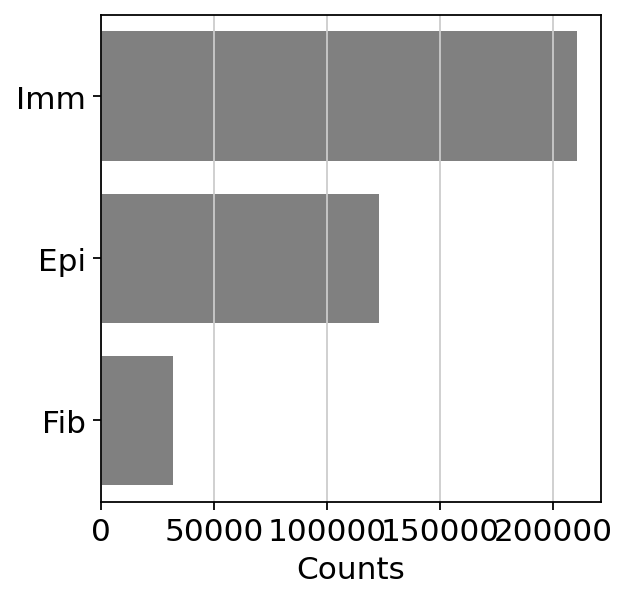

In [8]:
### have a look at cell nrs per sample ### 
temp=bc.tl.count_occurrence(adata,split_condition)
sns.barplot(y=temp.index,x=temp.Counts,color='gray',orient='h')

##### Transcript Capture Efficiency
This plot gives you an idea about the sequencing depth and if the sequencing has reached saturation or not.

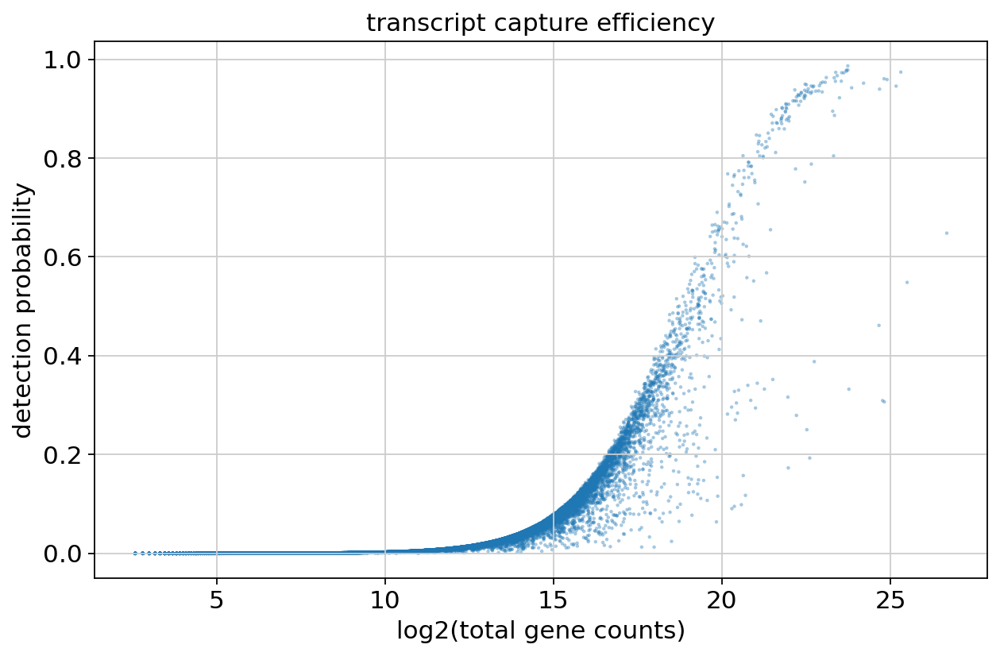

In [9]:
fig, ax = plt.subplots(1)
fig.set_figwidth(8)
fig.set_figheight(5)
fig.tight_layout()

bc.pl.transcript_capture_efficiency(adata,ax=ax)
fig.savefig(os.path.join(results_folder, 'figures/transcriptcaptureefficiency.png'), format='png', bbox_inches = 'tight') #save figure for QC report

##### Library Size distribution
This plot gives you an idea about the library size distribution in your dataset before processing.

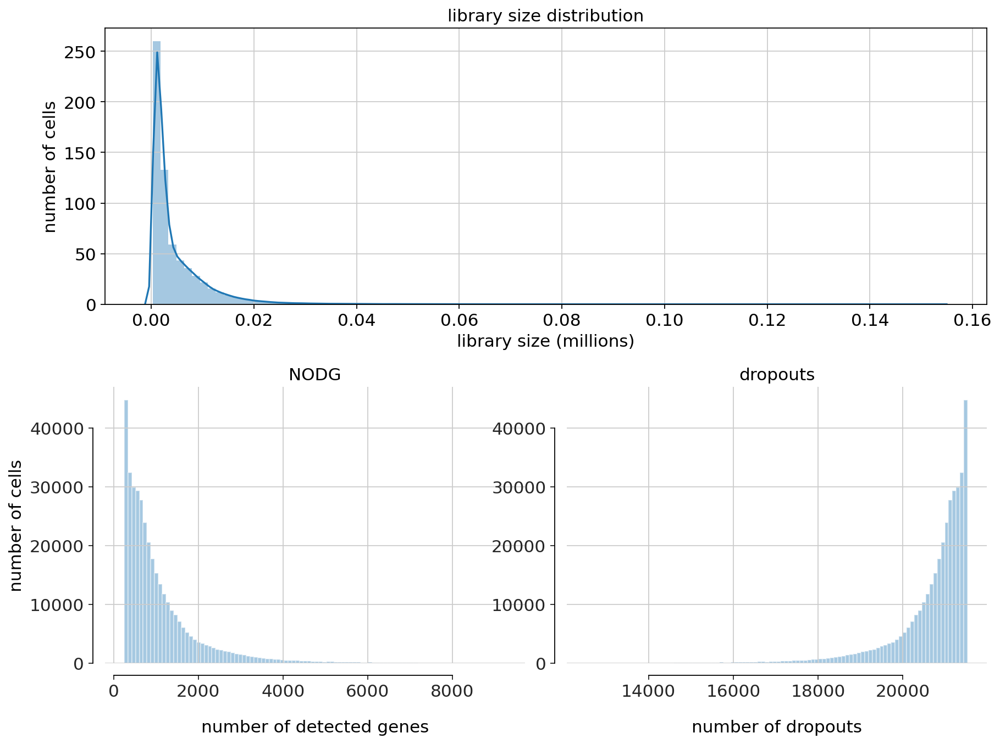

In [10]:
fig = bc.pl.librarysize_overview(adata, bins=100)
fig.savefig(os.path.join(results_folder, 'figures/librarysize.png'), format='png',bbox_inches = 'tight') #save figure for QC report

In [11]:
adata_unfiltered = adata.copy()

##### Selected Filtering Parameters

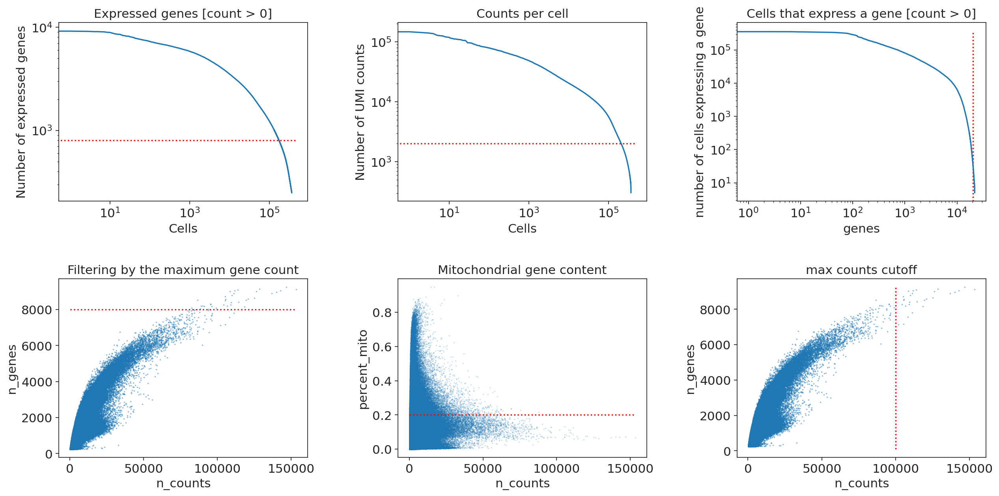

In [12]:
fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(ncols=3, nrows=2)
fig.set_figwidth(17)
fig.set_figheight(9)
fig.tight_layout(pad=4.5)

bc.pl.kp_genes(adata, min_genes=standard_min_genes, ax = ax1)
bc.pl.kp_counts(adata, min_counts=standard_min_counts, ax = ax2)
bc.pl.kp_cells(adata, min_cells=standard_min_cells, ax = ax3)
bc.pl.max_genes(adata, max_genes=standard_n_genes, ax = ax4)
bc.pl.max_mito(adata, max_mito=standard_percent_mito, annotation_type='SYMBOL', species=species, ax = ax5)
bc.pl.max_counts(adata, max_counts=standard_max_counts, ax=ax6)
fig.savefig(os.path.join(results_folder, 'figures/filtering_thresholds.png'), format='png', bbox_inches = 'tight') #save figure for QC report

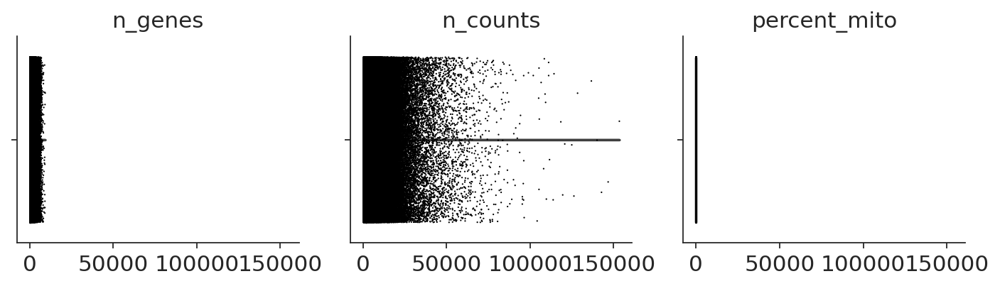

In [13]:
sc.pl.violin(adata, ['n_genes', 'n_counts', 'percent_mito'], jitter=0.4, multi_panel=True, save = '.before_filtering.png')

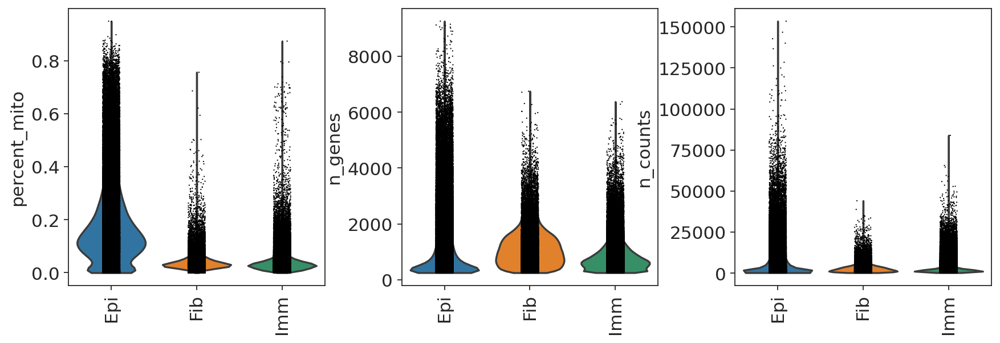

In [14]:
### check mitochondrial reads per sample 
sc.pl.violin(adata, ['percent_mito','n_genes', 'n_counts'], groupby=split_condition,jitter=0.1,rotation=90, save = '.before_filtering.split.png')

### First filtering on gene and cell counts

In [15]:
%%capture filtering1
adata = bc.st.filtering_cells_genes_min(adata, standard_min_cells, standard_min_genes, standard_min_counts)

LOG MESSAGE: After filtering for minimum number of cells and minimum number of expressed genes: 169741 cells, 20362 genes
LOG MESSAGE: 	Time for filtering: 16.884s


In [16]:
filtering1.show()

started with  365492  total cells and  21784  total genes
removed 190418 cells that did not express at least 800  genes
removed 5333 cells that did not have at least 2000 counts
removed 1422 genes that were not expressed in at least 30 cells
finished with 169741  total cells and 20362 total genes


### Second filtering on mitochondrial genes, and upper limit for gene number ###

In [17]:
%%capture filtering2
adata = bc.st.filtering_mito_genes_max(adata, standard_percent_mito, standard_n_genes, standard_max_counts)

LOG MESSAGE: After filtering for maximum number of expressed genes and max percent mito: 149733 cells, 20362 genes
LOG MESSAGE: 	Time for filtering: 9.898s


In [18]:
filtering2.show()

started with  169741  total cells and  20362  total genes
removed 37 cells that expressed more than 8000 genes
removed 4 cells that had more than 100000  counts
removed  19967  cells that expressed  20.0 percent mitochondrial genes or more
finished with 149733  total cells and 20362 total genes


### ! Remove the 1 MT-hi cell ###

In [19]:
#adata = bc.subset_adata(adata, adata.obs.get('Cluster') != 'MT-hi')
#adata.raw = adata
adata = adata[adata.obs.get('Cluster') != 'MT-hi',:].copy()

###  Filtered dataset characteristics

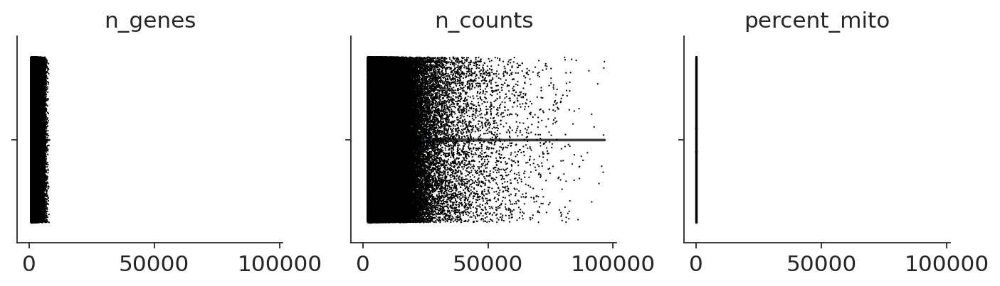

In [20]:
sc.pl.violin(adata, ['n_genes', 'n_counts', 'percent_mito'], jitter=0.4, multi_panel=True, save = '.after_filtering.png')

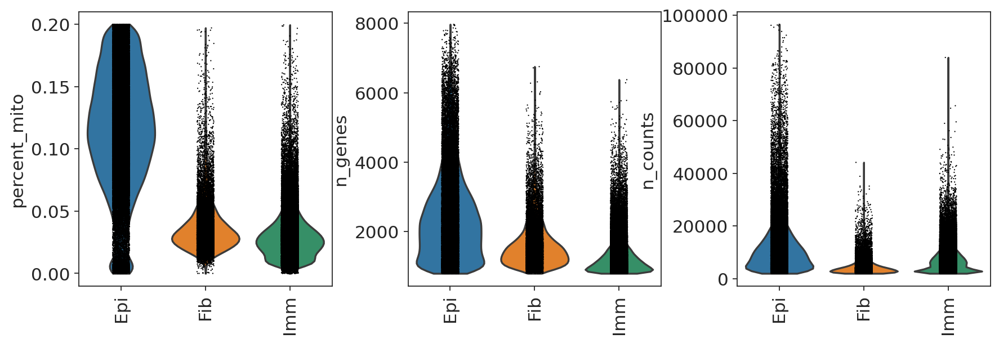

In [21]:
### check mitochondrial reads per sample 
sc.pl.violin(adata, ['percent_mito','n_genes', 'n_counts'], groupby=split_condition,jitter=0.1,rotation=90, save = '.after_filtering.split.png')

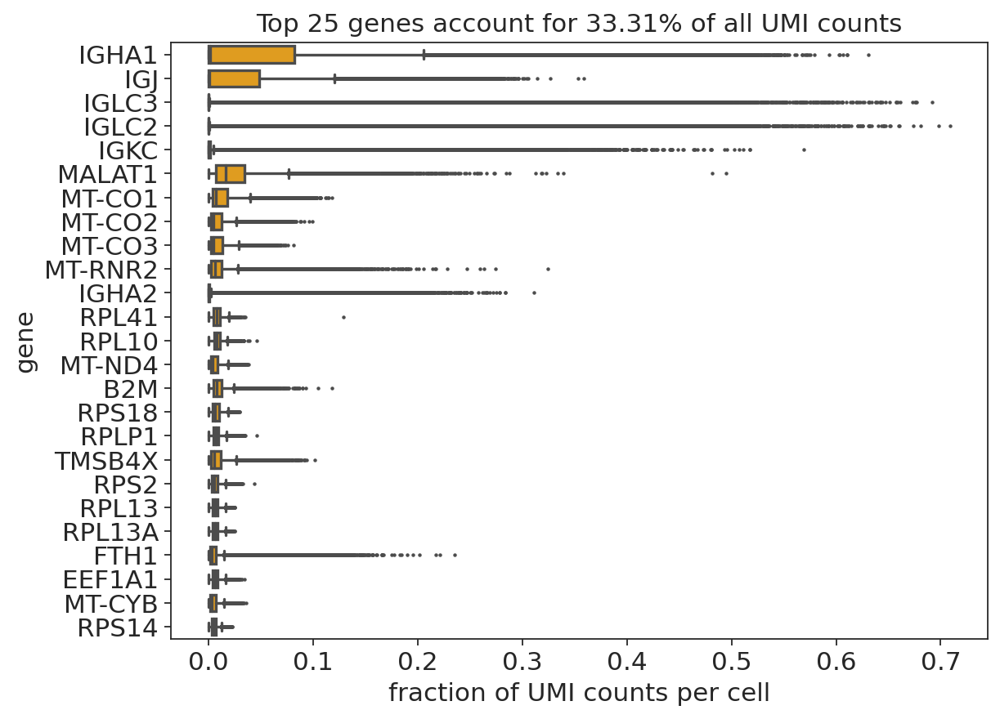

In [22]:
#display the top 25 genes in the dataset
fig, ax = plt.subplots(ncols=1, nrows=1, figsize = (8, 6))
bc.pl.top_genes_counts(adata=adata, top_n=25, ax = ax )
fig.savefig(os.path.join(results_folder, 'figures/top_genes.png'), format='png', bbox_inches = 'tight') #save figure for QC report

### Per-cell normalization, and output of normalized results ###

In [23]:
adata = bc.st.per_cell_normalize(adata, results_folder)

adata normalized per cell


LOG MESSAGE: Per cell normalization completed successfully.
LOG MESSAGE: 	Time for per-cell normalization: 11.349s


log1p values saved into adata.raw
writing out matrix.mtx ...
adata.X successfully written to matrix.mtx
genes successfully written out to genes.tsv
cellbarcodes successfully written out to barcodes.tsv


LOG MESSAGE: cp10k values exported to file.
LOG MESSAGE: 	Time for cp10k export: 751.371s


annotation successfully written out to metadata.tsv


<Figure size 320x320 with 0 Axes>

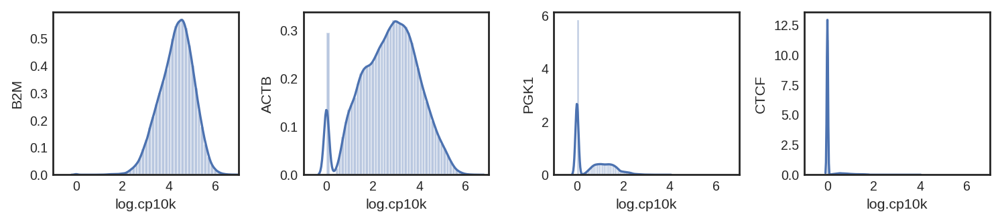

In [24]:
# Further QC: dynamic range of ubi/marker genes
fig = plt.figure()
sns.set(font_scale=0.8)
plt.style.use('seaborn-v0_8-white')
fig = plt.figure(figsize=(len(dynrange)*2.8,2))
fig.subplots_adjust(hspace=0.2, wspace=0.35)
for i in range(1,len(dynrange)+1):
    ax = fig.add_subplot(1, len(dynrange), i)
    myg=dynrange[i-1]
    try:
        g=sns.histplot(adata.raw[:,myg].X.toarray(), norm_hist=True)
    except:
        print( myg + ' can not be plotted')
    ax.set(xlabel='log.cp10k',ylabel=myg)
    g.set_xlim(-1, 7)

### Regression steps before feature selection (highly variable genes) for clustering

log1p taken of adata
'n_counts' and 'percent_mito' regressed out


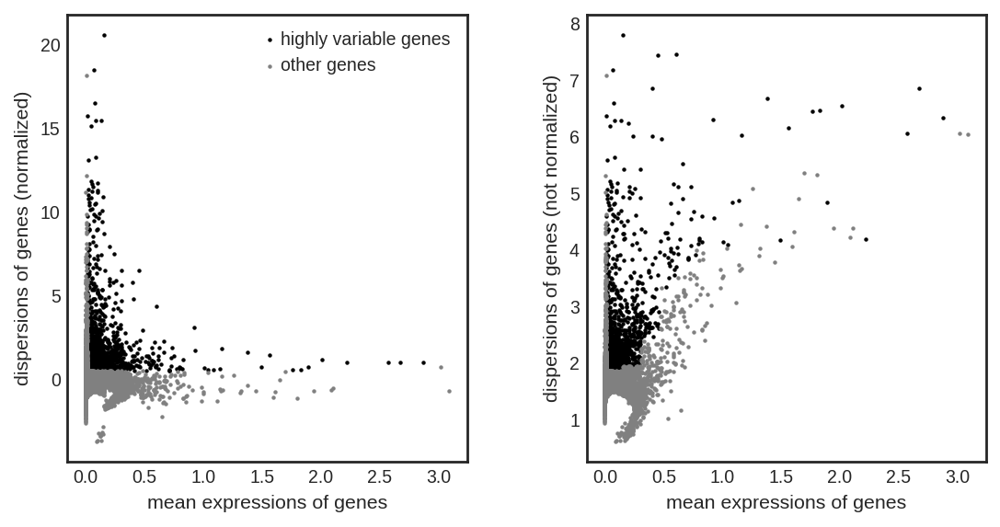

After feature selection of highly variable genes: 149732 cells, 1565 genes
adata scaled with max_value set to 10


In [25]:
sc.pp.log1p(adata)
print('log1p taken of adata')

adata = adata.copy()
sc.pp.regress_out(adata, ['n_counts', 'percent_mito'])
print("'n_counts' and 'percent_mito' regressed out")

sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5, inplace=True)
sc.pl.highly_variable_genes(adata, save='.hvg.png', show=True)
adata = adata[:, adata.var.highly_variable == True]
print('After feature selection of highly variable genes: ' +
             str(adata.shape[0])+' cells, ' + str(adata.shape[1])+' genes')

sc.pp.scale(adata, max_value=10)
print('adata scaled with max_value set to 10')

In [26]:
adata

AnnData object with n_obs × n_vars = 149732 × 1565
    obs: 'CELL', 'Cluster', 'Health', 'Location', 'Subject', 'celltype_highlevel', 'nGene', 'nUMI', 'original_name', 'percent_mito', 'n_counts', 'n_genes'
    var: 'ENSEMBL', 'SYMBOL', 'n_cells', 'total_counts', 'frac_reads', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'celltype_highlevel_colors', 'log1p', 'hvg'

### Feature selection (highly variable genes) for clustering (skipped) ###

In [27]:
#adata = bc.st.highly_variable_genes(adata)

### Regression steps, and output of regressed data (skipped) ###

In [28]:
#adata 

In [29]:
# RMK : AS OF FEB 2020 there is a bug in scanpy regress out if scanpy installed with PIP (see https://github.com/theislab/scanpy/issues/707)
# Before the fix is available, one should coopy the data toprevet it. hence the adata = adata.copy()
#adata = adata.copy()
#adata = bc.st.regress_out(adata, results_folder)

### Batch correction and PCA neighbor analysis and UMAP

The standard workflow uses bbknn as  batch correction method.


Using random_state = 0 for all the following calculations
PCA calculated using svd_solver = 'arpack'. PCA multiplied by -1 to match Seurat output.


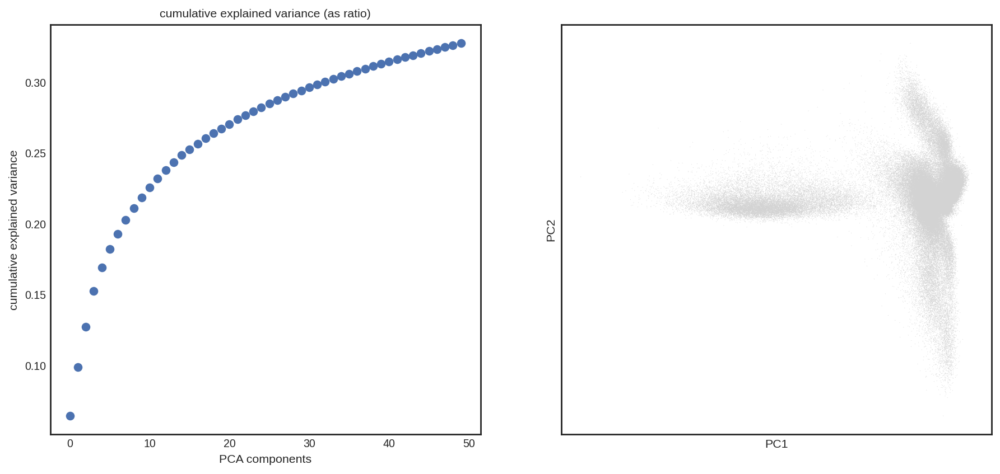

LOG MESSAGE: Neighborhood analysis completed, and UMAP generated.
LOG MESSAGE: 	 Time for PCA, nearest neighbor calculation and UMAP generation: 471.213s


UMAP coordinates calculated.


LOG MESSAGE: Metadata containing 3 PCAs and UMAP coordinates exported successfully to file.
LOG MESSAGE: Time for export: 1.66s


results successfully written out to 'analysis_metadata.tsv'


In [30]:
if (batch_to_correct != 'None'):
    #save a copy of uncorrected in case we need it for something later
    adata_uncorrected = adata.copy()
    adata.obs['batch'] = adata.obs[batch_to_correct]
    adata = bc.st.pca_neighbors_umap(adata,results_folder, method='bbknn')
else:
    adata = bc.st.pca_neighbors_umap(adata, results_folder)

### Clustering ###

leiden clustering performed with a resolution of 1


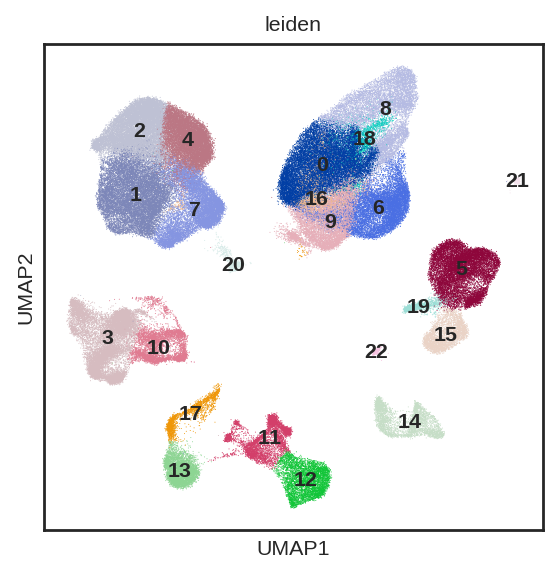

LOG MESSAGE: leidenclustering done. Found 23 clusters.
LOG MESSAGE: 	Time for leiden clustering: 297.64s
LOG MESSAGE: Marker gene detection performed on a per-cluster basis using the method wilcoxon.
LOG MESSAGE: 	Time for marker gene detection: 364.117s


rank genes per cluster calculated using method wilcoxon.
mapping of cells to  leiden exported successfully to cell2labels.tsv
average.gct exported successfully to file
fract_pos.gct exported successfully to file
labelinfo.tsv successfully written out
./analyzed/standard_workflow_besca2_0_regress_out_before_hvg_selection/labelings/leiden/WilxRank.gct written out
./analyzed/standard_workflow_besca2_0_regress_out_before_hvg_selection/labelings/leiden/WilxRank.pvalues.gct written out


LOG MESSAGE: Cluster level analysis and marker genes exported to file.
LOG MESSAGE: 	Time for export of cluster level analysis: 19.375s


./analyzed/standard_workflow_besca2_0_regress_out_before_hvg_selection/labelings/leiden/WilxRank.logFC.gct written out


In [31]:
# leiden clustering is the default 
adata = bc.st.clustering(adata, results_folder)

In [32]:
# everything that was done so far goes to the .h5ad file for later use
adata.write(results_file)
print(results_file)

./analyzed/standard_workflow_besca2_0_regress_out_before_hvg_selection/standard_workflow_besca2_0_regress_out_before_hvg_selection.h5ad


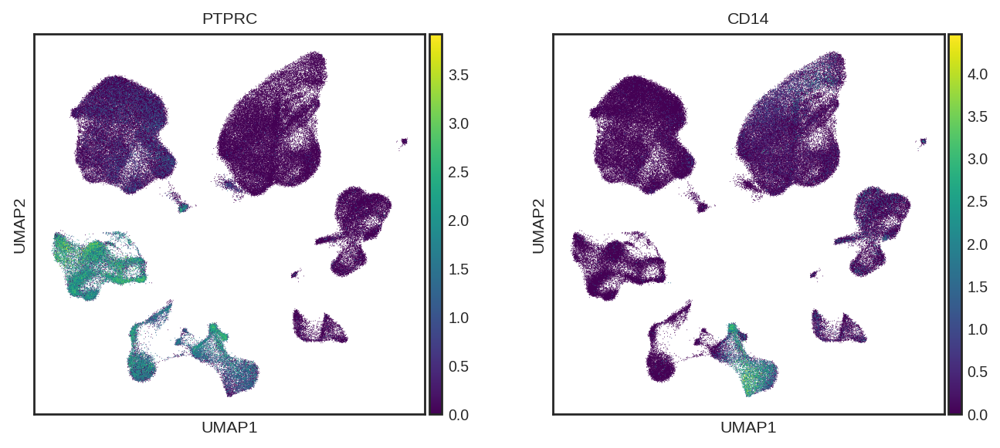

In [33]:
sc.pl.umap( adata, color=['PTPRC', 'CD14'], color_map = 'viridis')

### Additional Labeling ###

(if specified) based on external annotation in "metadata.tsv"  the additional labeling will be exported to file and the fract_pos.gct and average.gct files generated

In [34]:
if (labeling_to_use != 'None'):
    adata = bc.st.additional_labeling(adata, labeling_to_use, labeling_name, labeling_description, labeling_author, results_folder)

mapping of cells to  Cluster exported successfully to cell2labels.tsv
average.gct exported successfully to file
fract_pos.gct exported successfully to file
labelinfo.tsv successfully written out


LOG MESSAGE: Marker gene detection performed on a per-label basis using the method wilcoxon.
LOG MESSAGE: 	Time for marker gene detection: 474.673s


rank genes per label calculated using method wilcoxon.
./analyzed/standard_workflow_besca2_0_regress_out_before_hvg_selection/labelings/Smillie2019/WilxRank.gct written out
./analyzed/standard_workflow_besca2_0_regress_out_before_hvg_selection/labelings/Smillie2019/WilxRank.pvalues.gct written out


LOG MESSAGE: Label level analysis and marker genes exported to file.
LOG MESSAGE: 	Time for export of cluster level analysis: 499.476s


./analyzed/standard_workflow_besca2_0_regress_out_before_hvg_selection/labelings/Smillie2019/WilxRank.logFC.gct written out


### Complete log-file

In [35]:
logging.info('Entire workflow completed.')
logging.info('\tTime for entire workflow: '+str(round(time.time()-start0, 3))+'s')

LOG MESSAGE: Entire workflow completed.
LOG MESSAGE: 	Time for entire workflow: 7868.84s


### Write QC Report

In [36]:
bc.st.write_qc(adata_unfiltered = adata_unfiltered, 
                 adata_filtered = adata,
                 version = version, 
                 analysis_name = analysis_name, 
                 standard_min_genes = standard_min_genes, 
                 standard_min_cells = standard_min_cells, 
                 standard_min_counts = standard_min_counts, 
                 standard_percent_mito = standard_percent_mito, 
                 standard_max_counts = standard_max_counts,
                 standard_n_genes = standard_n_genes,
                 filtering_output1 = filtering1,
                 filtering_output2 = filtering2,
                 results_folder = results_folder,
                 css_path = os.path.join(os.path.dirname(bc.__file__),'st', 'style.css'))
logging.info('QC Report generated and saved as .html')

LOG MESSAGE: QC Report generated and saved as .html


### Comparison to original standard workflow

In [37]:
adata

AnnData object with n_obs × n_vars = 149732 × 1565
    obs: 'CELL', 'Cluster', 'Health', 'Location', 'Subject', 'celltype_highlevel', 'nGene', 'nUMI', 'original_name', 'percent_mito', 'n_counts', 'n_genes', 'batch', 'leiden'
    var: 'ENSEMBL', 'SYMBOL', 'n_cells', 'total_counts', 'frac_reads', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'celltype_highlevel_colors', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'rank_genes_groups'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [38]:
# Read the results file from the original standard workflow
adata_std = bc.datasets.Smillie2019_processed()
adata_std.obs = adata_std.obs.set_index(adata_std.obs['CELL'])
adata_std

AnnData object with n_obs × n_vars = 149732 × 2196
    obs: 'CELL', 'Cluster', 'Health', 'Location', 'Subject', 'celltype_highlevel', 'nGene', 'nUMI', 'original_name', 'percent_mito', 'n_counts', 'n_genes', 'batch', 'leiden', 'dblabel', 'celltype', 'cluster_celltype', 'Type'
    var: 'ENSEMBL', 'SYMBOL', 'n_cells', 'total_counts', 'frac_reads'
    uns: 'Cluster_colors', 'Location_colors', 'Type_colors', 'celltype_highlevel_colors', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

HVGs regress out before feature selection: 1565
HVGs feature selection before regress out: 2196
HVGs intersection: 1500


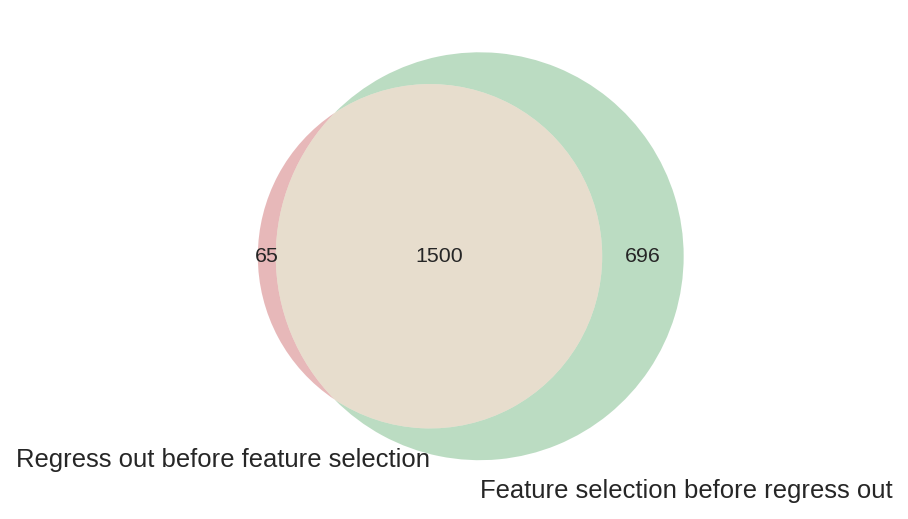

In [39]:
# Intersection of highly variable genes (HVG) and Venn diagram

hvg_adata = adata.var_names
hvg_adata_std = adata_std.var_names
hvg_intersection = list(set(hvg_adata) & set(hvg_adata_std))

print('HVGs regress out before feature selection: ' + str(len(hvg_adata)))
print('HVGs feature selection before regress out: ' + str(len(hvg_adata_std)))
print('HVGs intersection: ' + str(len(hvg_intersection)))

from matplotlib_venn import venn2
venn2(
    subsets = (len(hvg_adata)-len(hvg_intersection), len(hvg_adata_std)-len(hvg_intersection), len(hvg_intersection)), 
    set_labels = ('Regress out before feature selection', 'Feature selection before regress out')
)

In [42]:
# Add labelings from original workflow for comparison
adata.obs = adata.obs.join(adata_std.obs['dblabel'])
adata.obs = adata.obs.join(adata_std.obs['leiden'], rsuffix='_std')

acc: 0.64
f1: 0.66
ami: 0.87
ari: -1.92
silhouette leiden_std: 0.29
silhouette leiden: 0.34
pair confusion matrix:              0           1
0  20529916060   251902784
1    365917340  1271785908


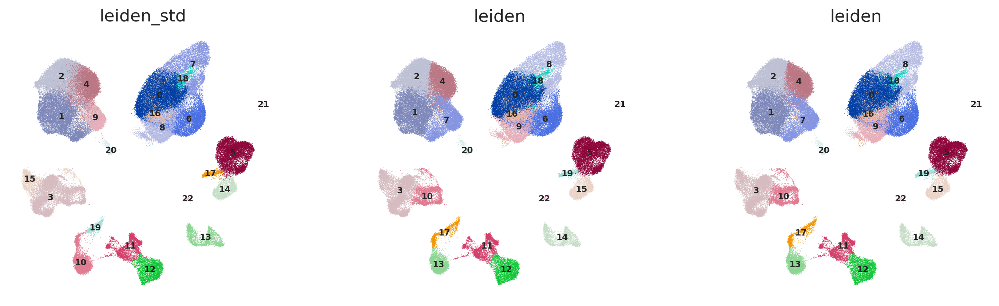

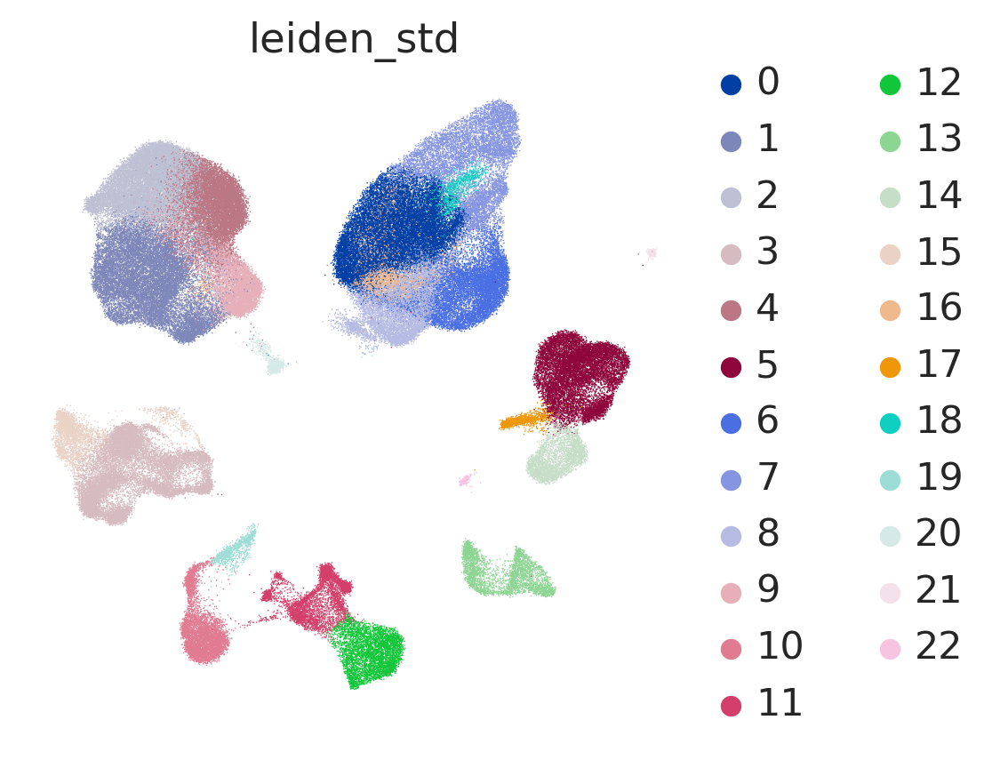

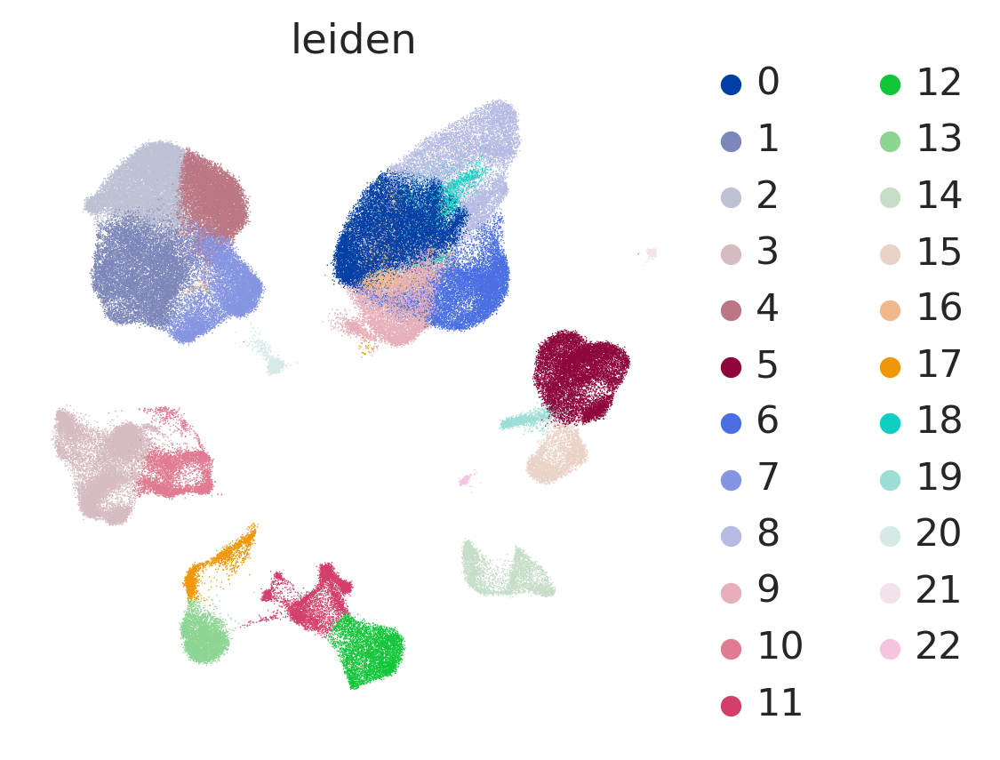

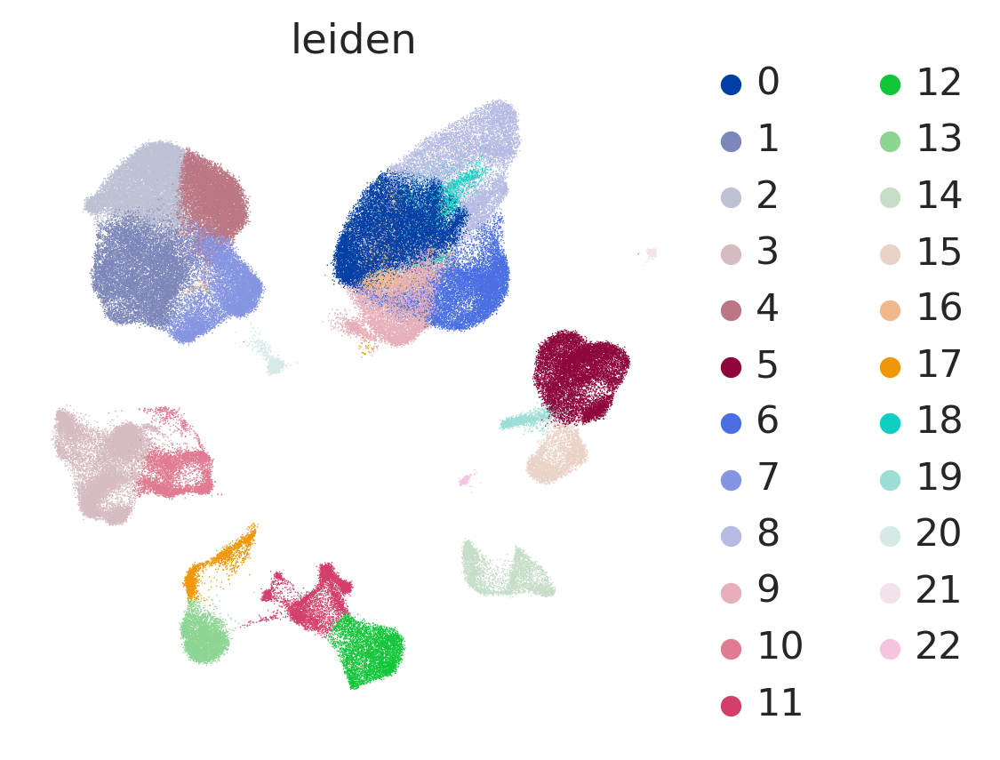

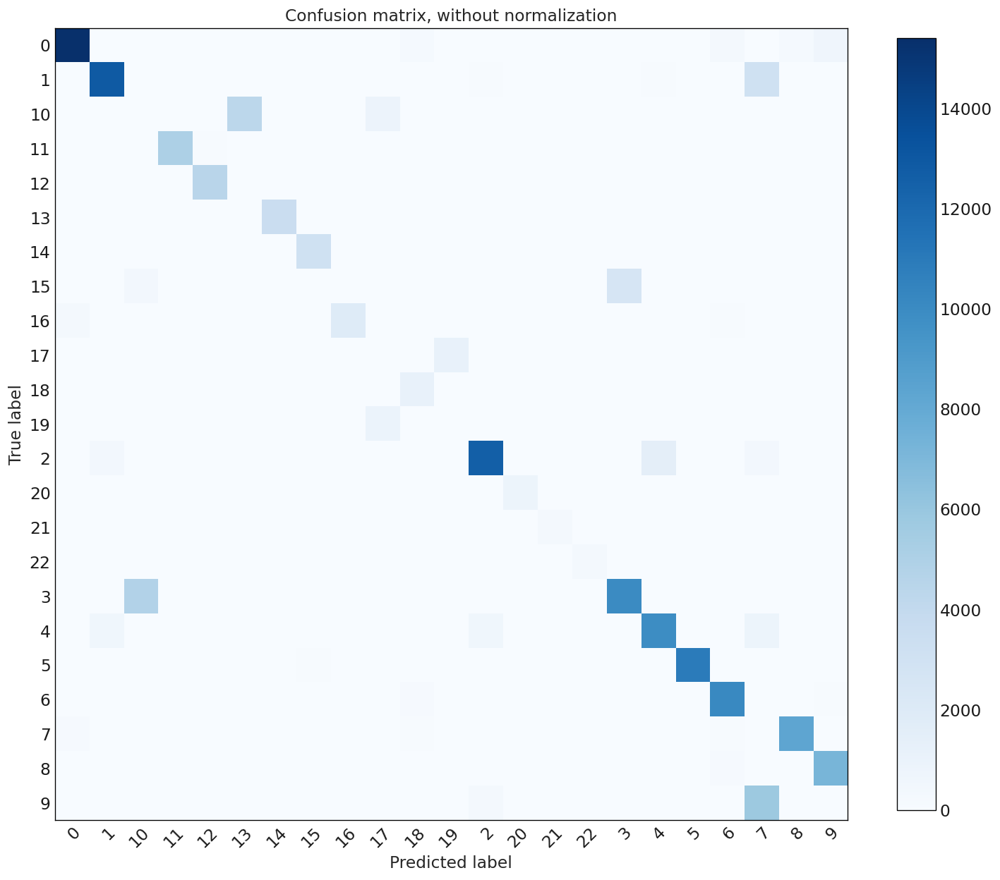

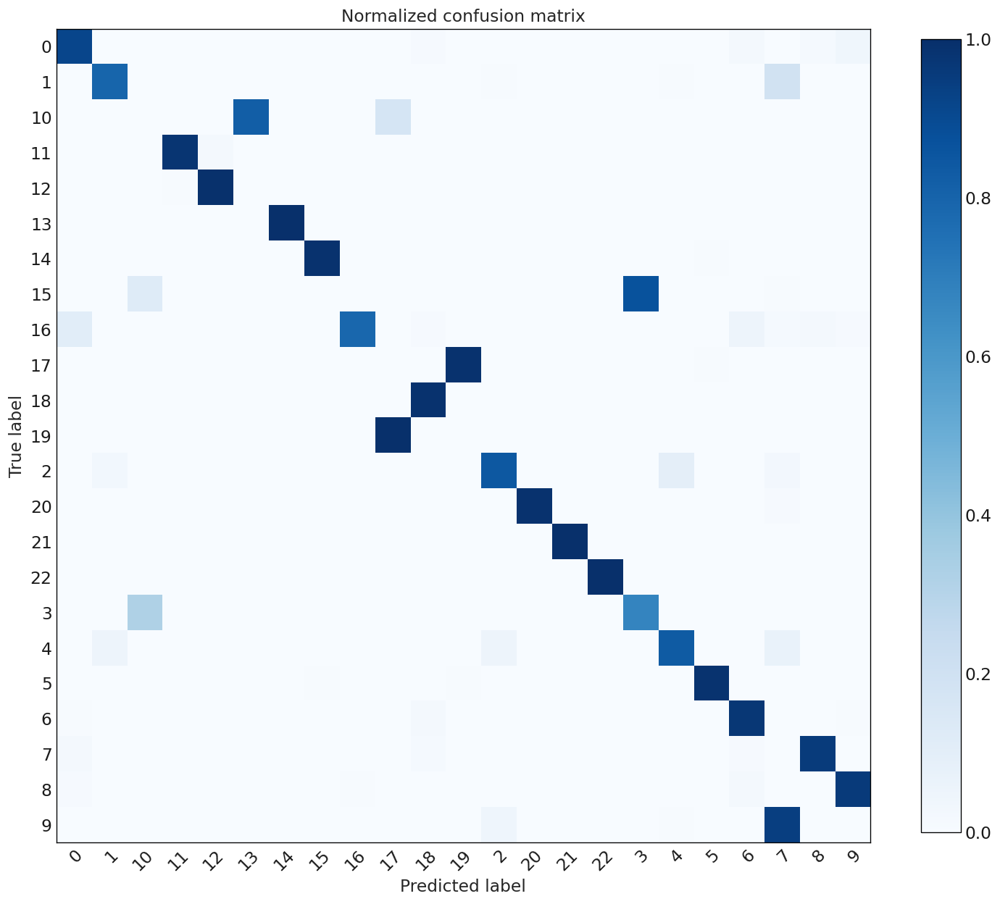

In [43]:
bc.tl.report(adata_pred=adata, celltype='leiden_std', method='regress_out_before_hvg_selection', analysis_name=analysis_name,
                        test_dataset='adata_new', name_prediction='leiden', name_report='compare_leiden', use_raw=False,
                        remove_nonshared=False, clustering='leiden', asymmetric_matrix=True, delimiter='\t', verbose=True)

acc: 0.0
f1: 0.0
ami: 0.72
ari: 0.17
silhouette dblabel: 0.14
silhouette leiden: 0.34
pair confusion matrix:              0           1
0  18706883258   460965994
1   2188950142  1062722698


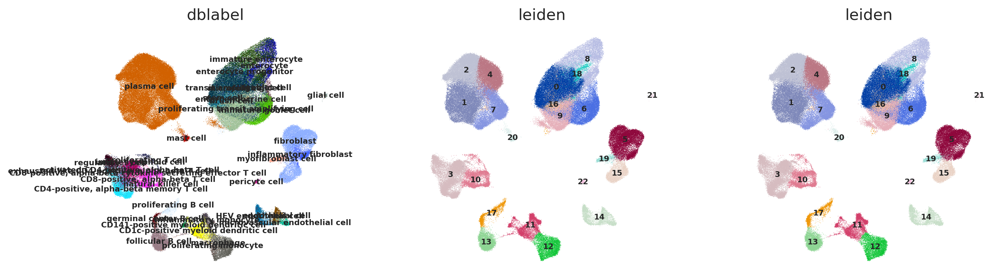

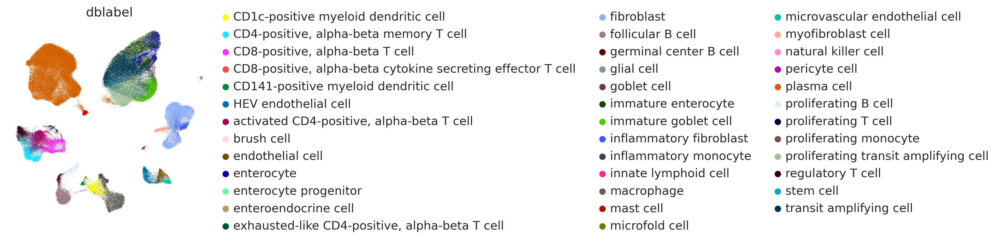

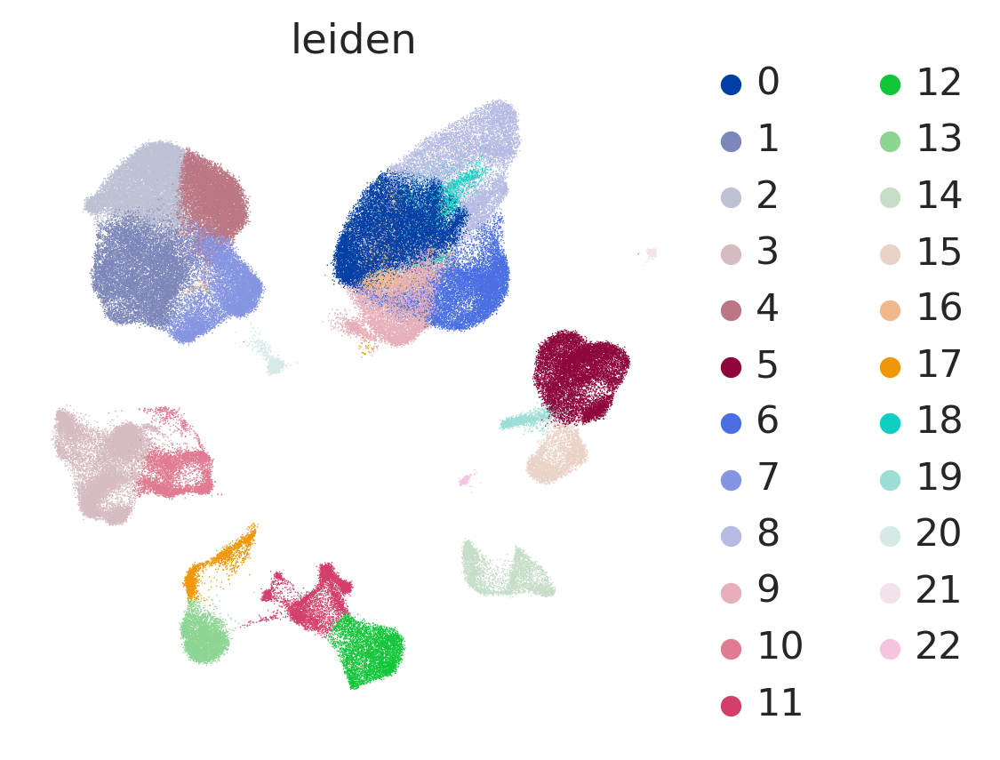

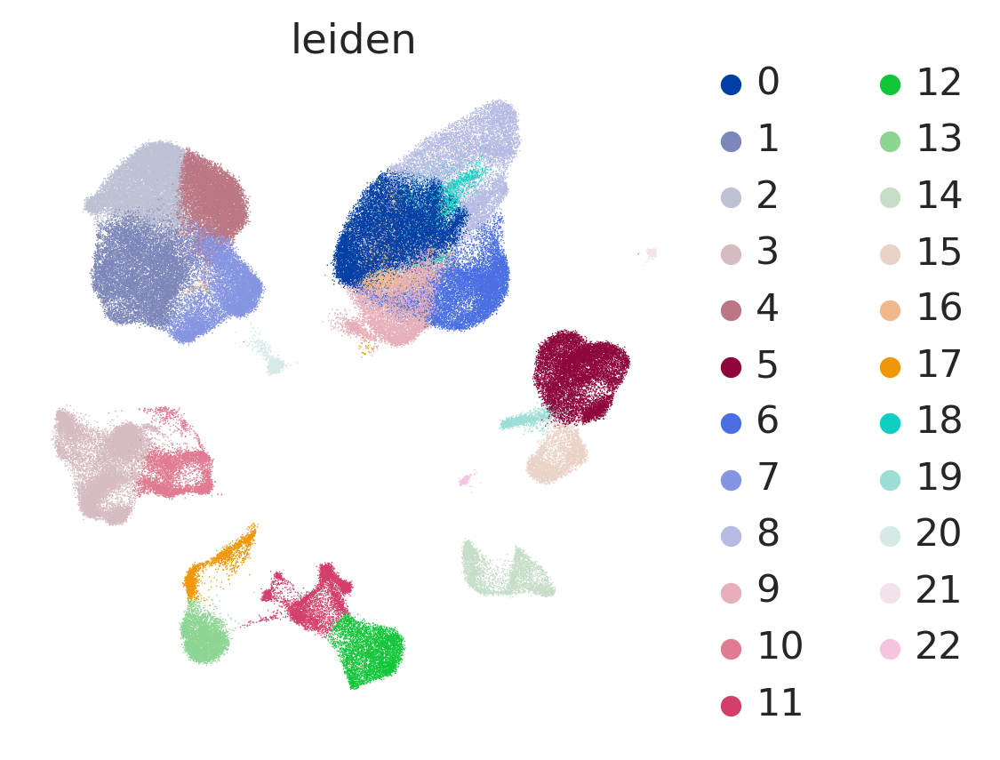

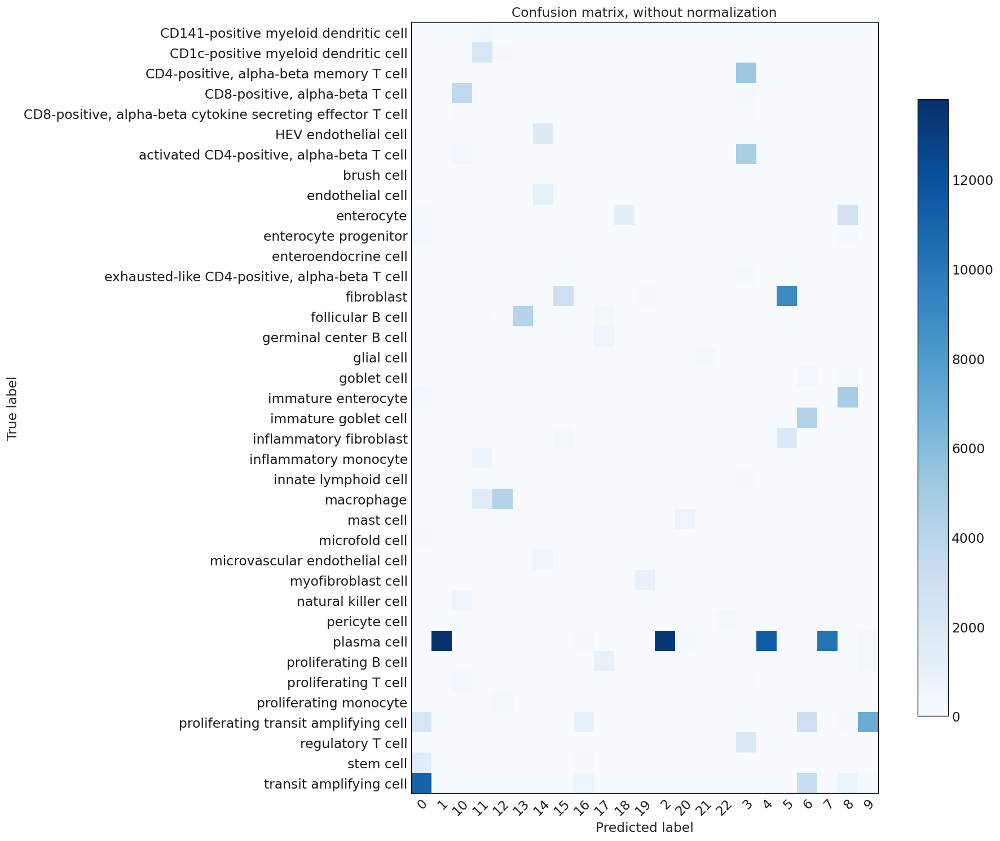

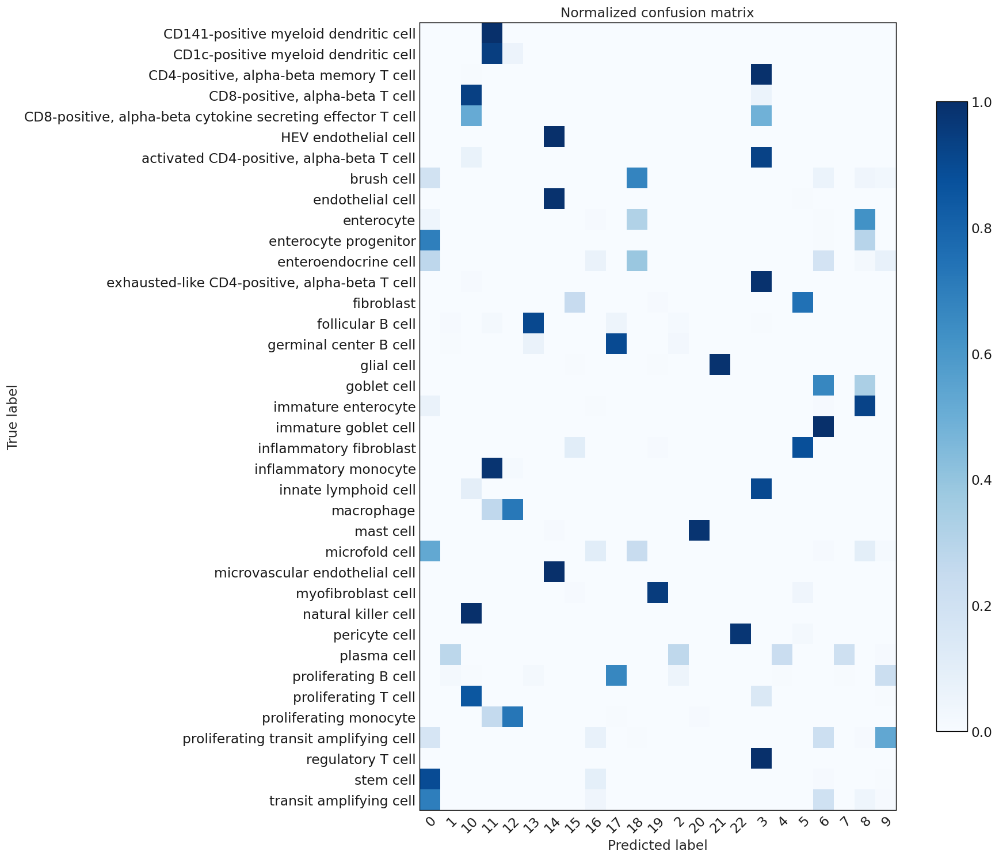

In [44]:
bc.tl.report(adata_pred=adata, celltype='dblabel', method='regress_out_before_hvg_selection', analysis_name=analysis_name,
                        test_dataset='adata_new', name_prediction='leiden', name_report='compare_dblabel', use_raw=False,
                        remove_nonshared=False, clustering='leiden', asymmetric_matrix=True, delimiter='\t', verbose=True)

acc: 0.0
f1: 0.0
ami: 0.72
ari: -16.71
silhouette Cluster: 0.14
silhouette leiden: 0.34
pair confusion matrix:              0          1
0  18854733740  558443484
1   2041099660  965245208


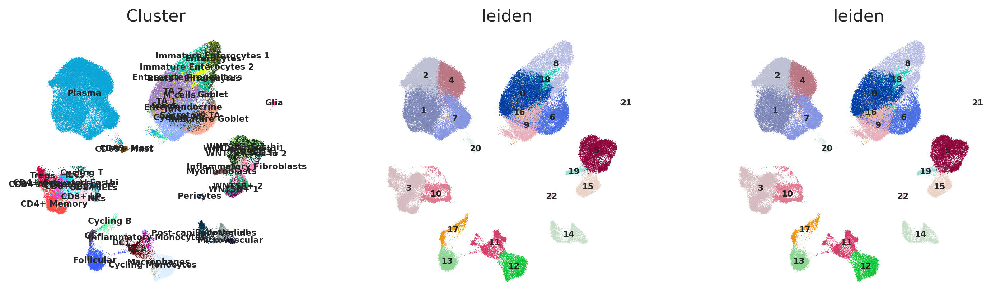

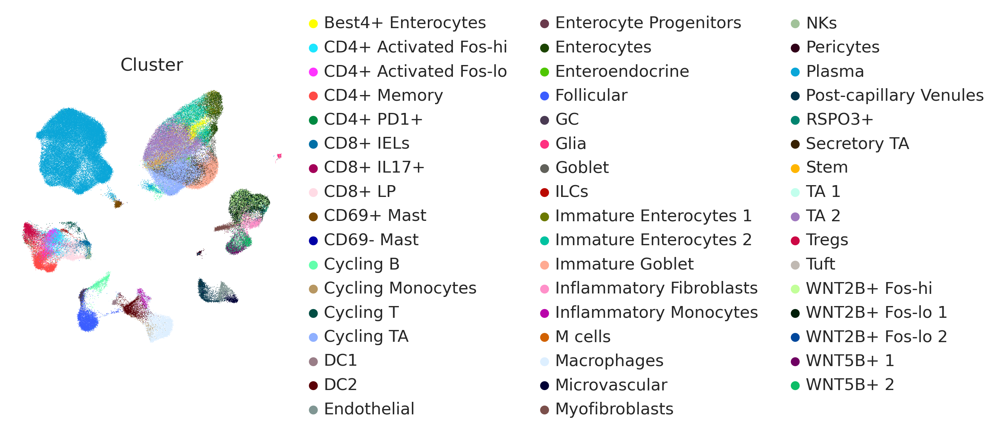

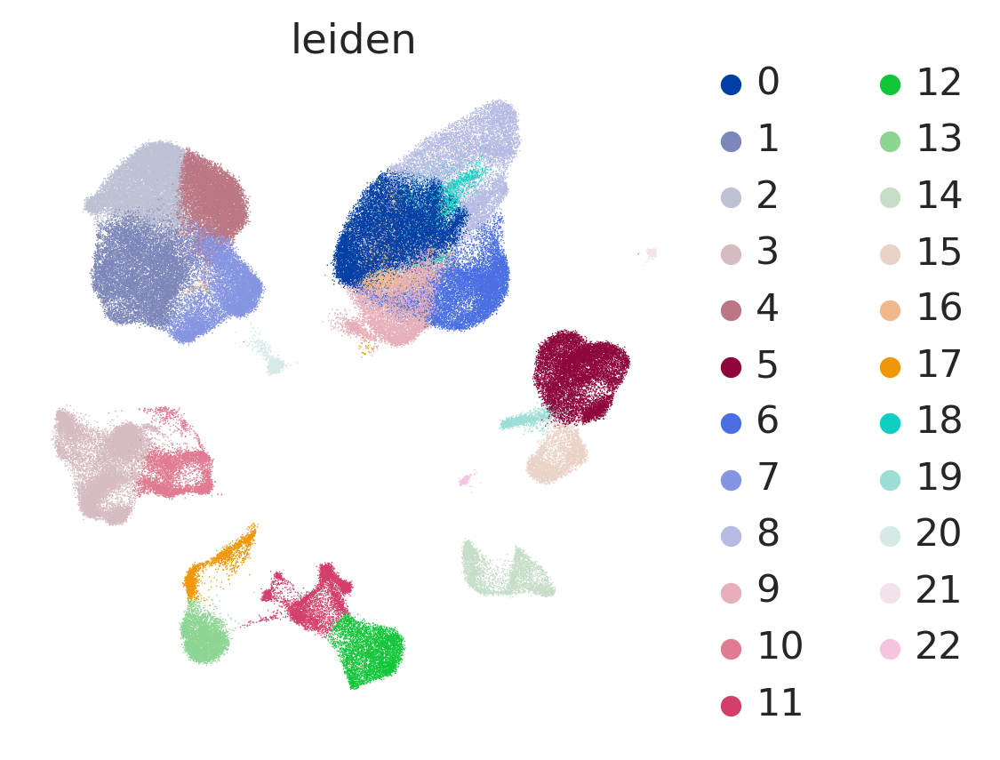

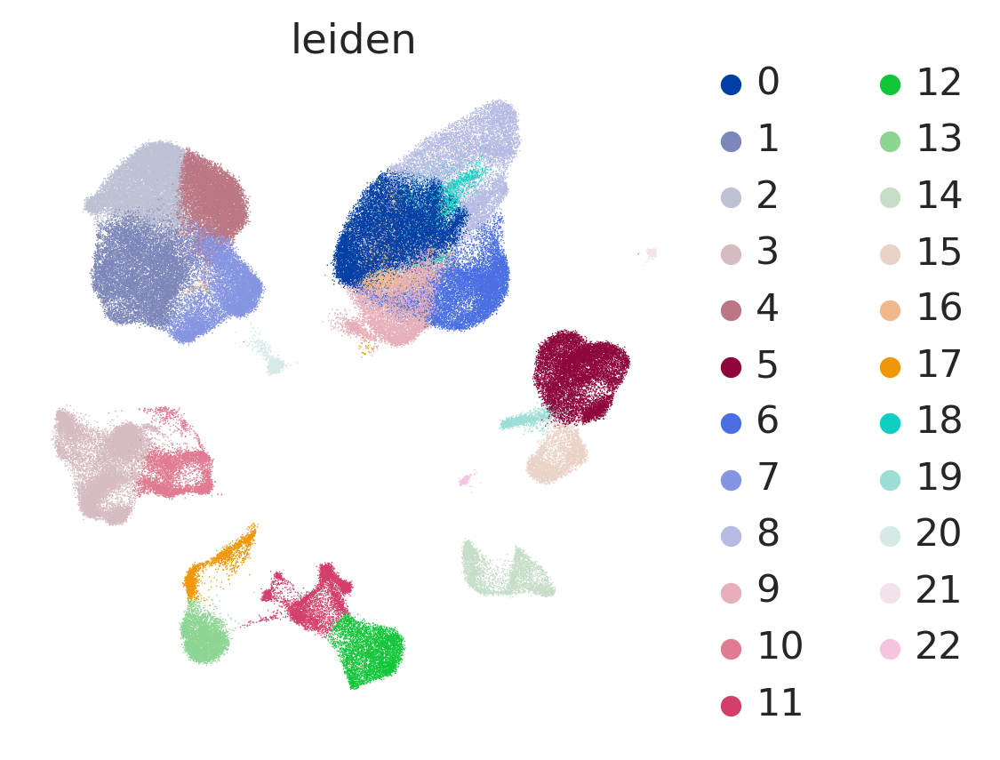

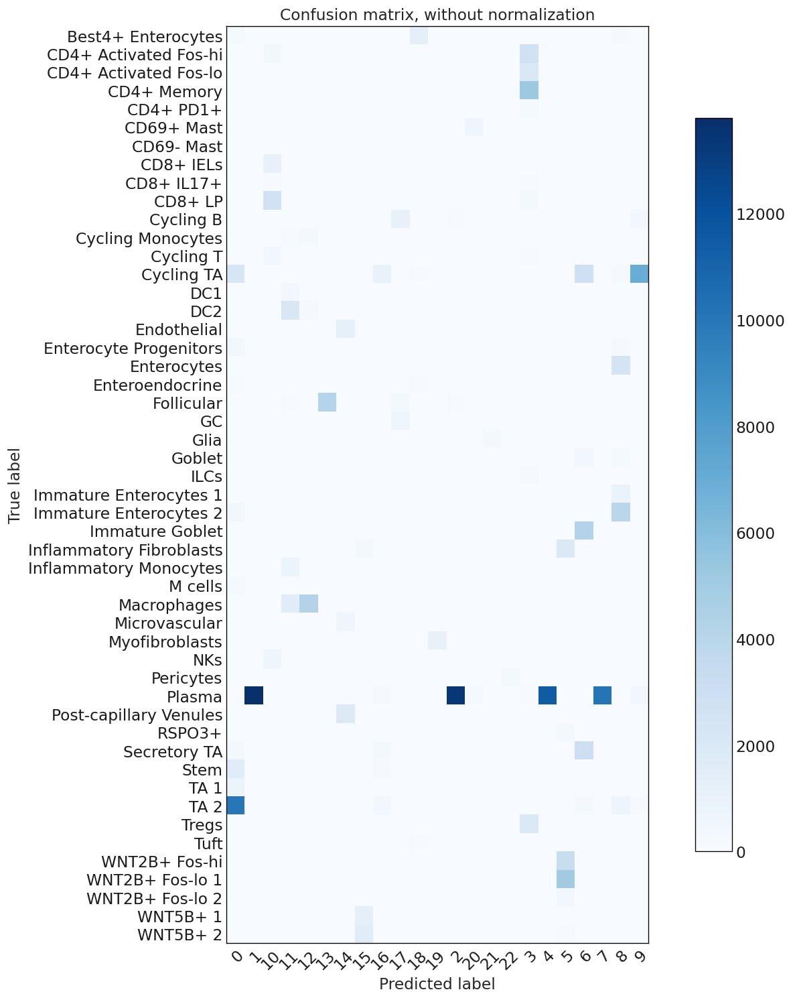

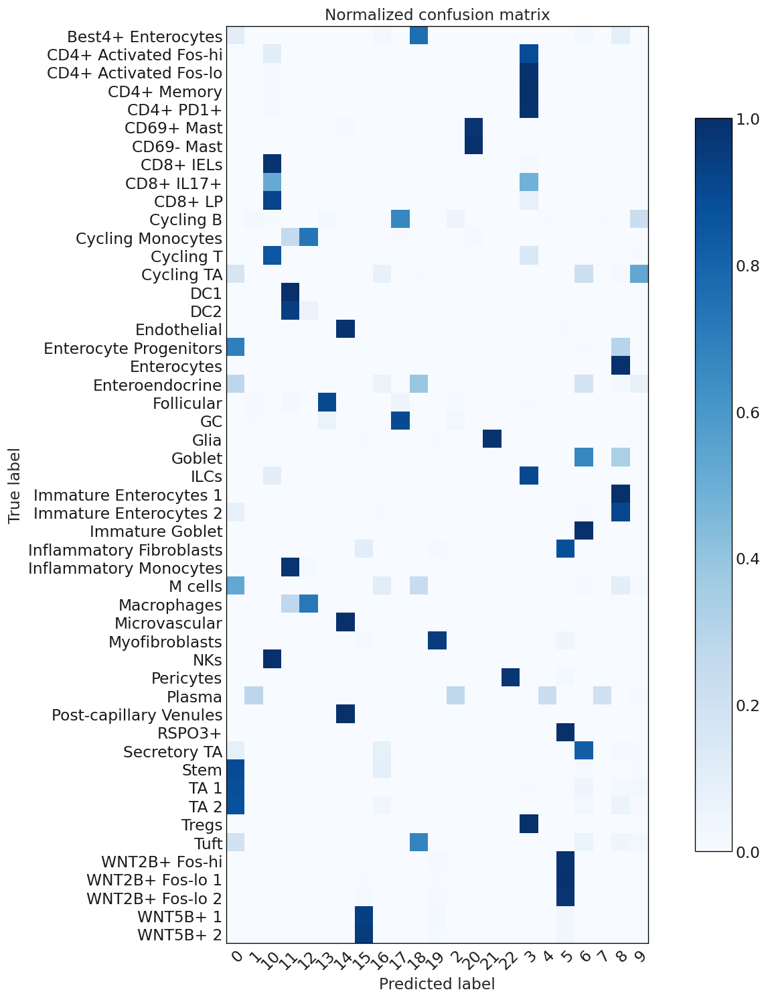

In [45]:
bc.tl.report(adata_pred=adata, celltype='Cluster', method='regress_out_before_hvg_selection', analysis_name=analysis_name,
                        test_dataset='adata_new', name_prediction='leiden', name_report='compare_Cluster', use_raw=False,
                        remove_nonshared=False, clustering='leiden', asymmetric_matrix=True, delimiter='\t', verbose=True)

In [46]:
# Assess the original workflow and add new clustering for comparison
adata_std.obs = adata_std.obs.join(adata.obs['leiden'], rsuffix='_new')

acc: 0.64
f1: 0.62
ami: 0.87
ari: -1.92
silhouette leiden_new: 0.28
silhouette leiden: 0.27
pair confusion matrix:              0           1
0  20529916060   365917340
1    251902784  1271785908


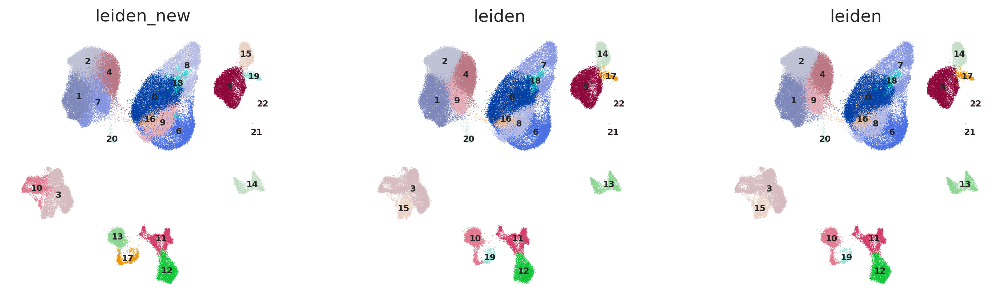

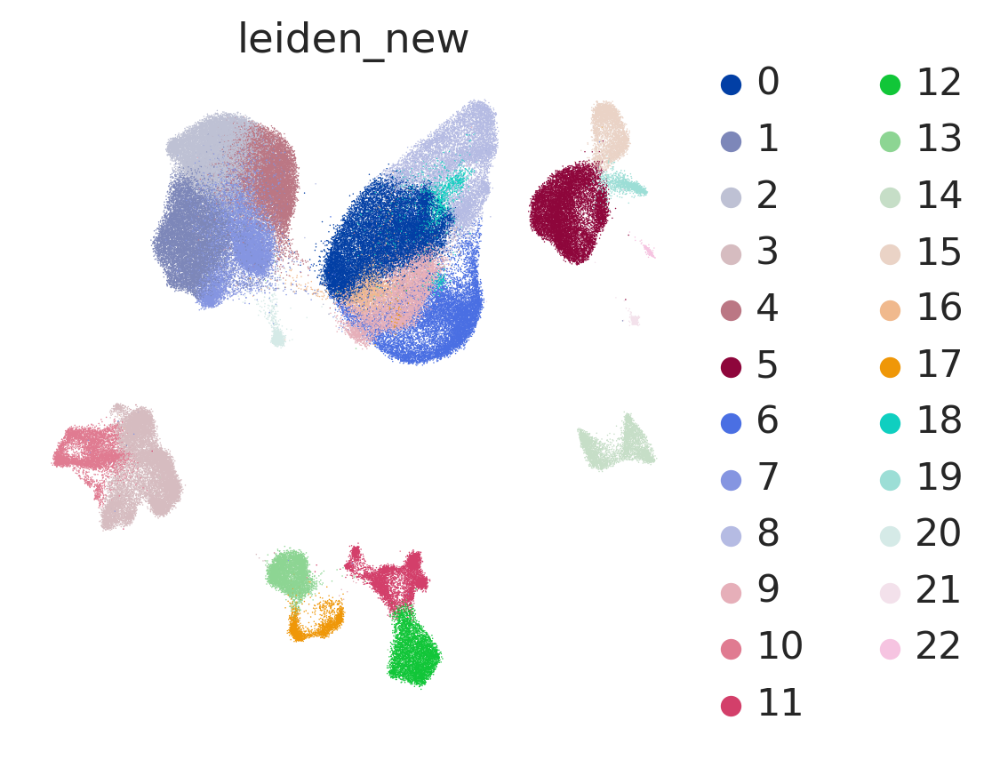

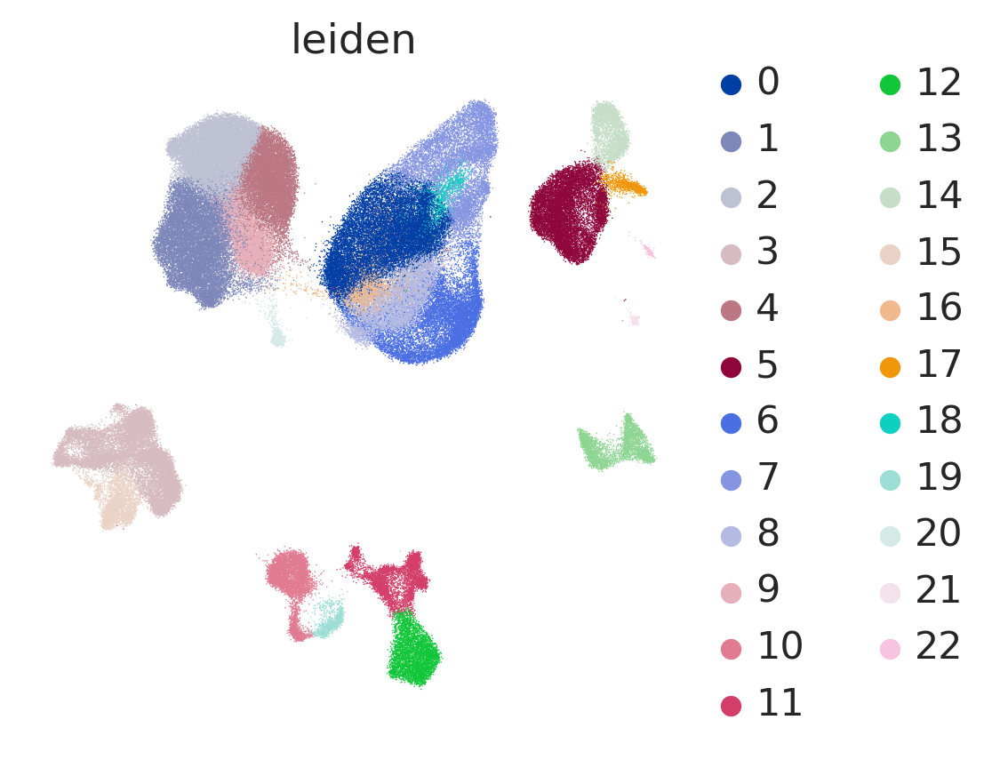

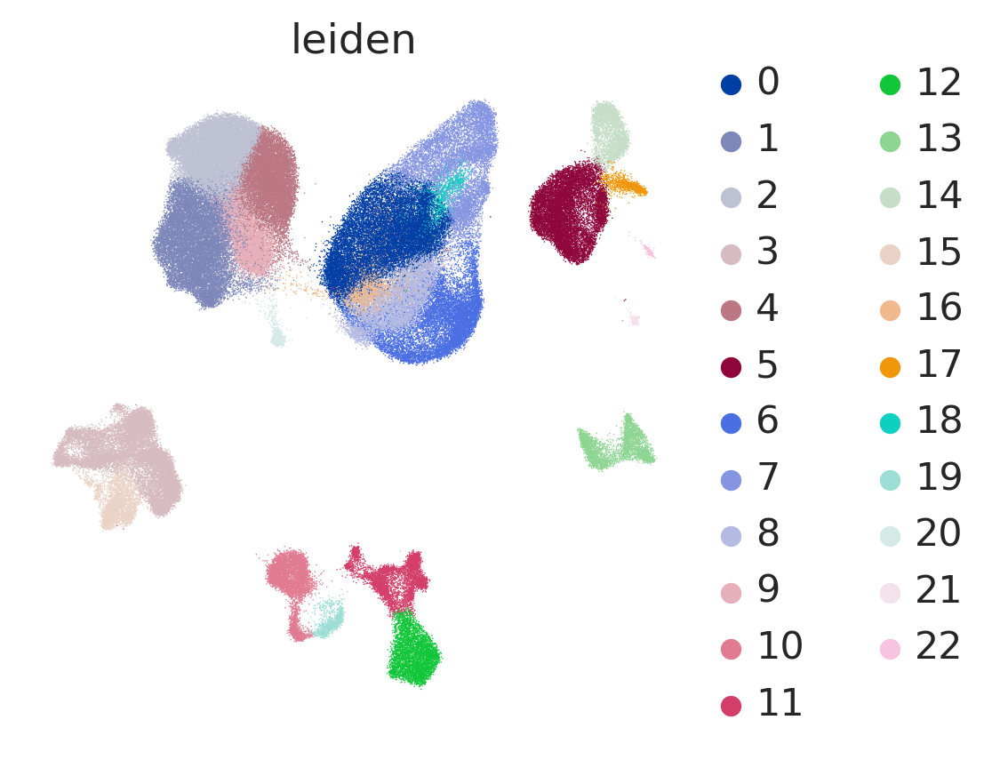

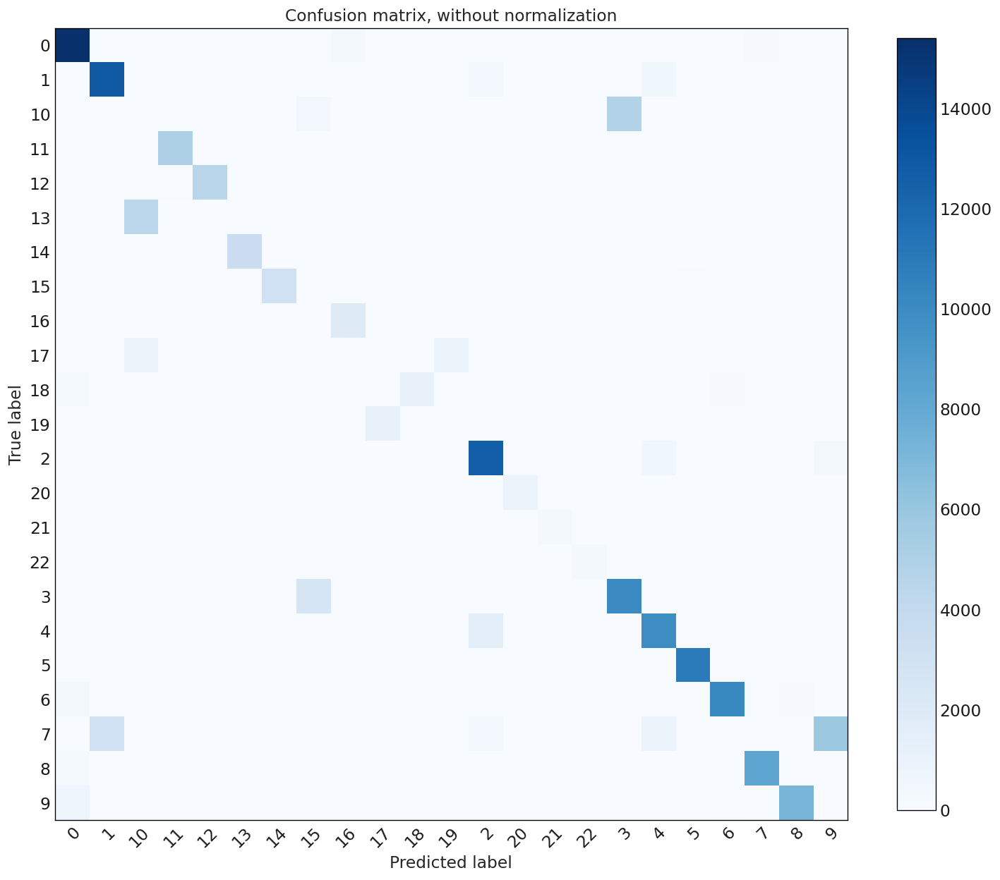

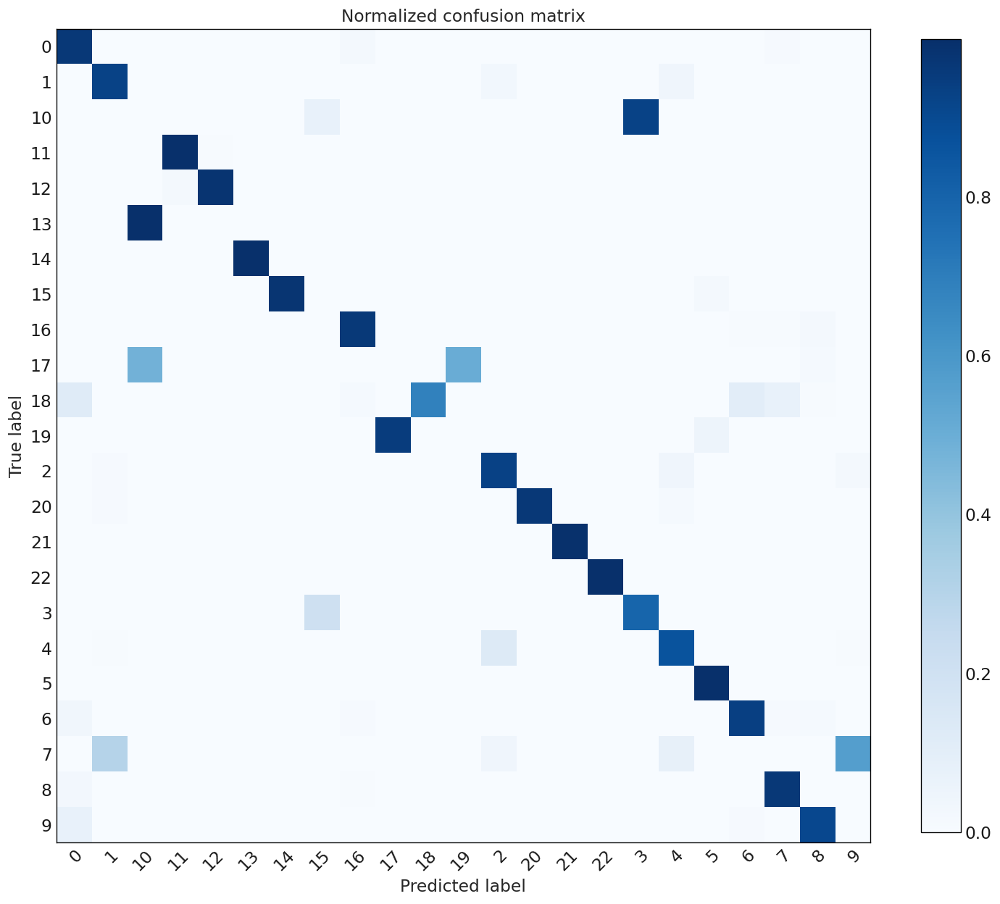

In [47]:
bc.tl.report(adata_pred=adata_std, celltype='leiden_new', method='hvg_selection_before_regress_out', analysis_name='standard_workflow_besca2_0',
                        test_dataset='adata_std', name_prediction='leiden', name_report='compare_leiden', use_raw=False,
                        remove_nonshared=False, clustering='leiden', asymmetric_matrix=True, delimiter='\t', verbose=True)

acc: 0.0
f1: 0.0
ami: 0.71
ari: 0.33
silhouette dblabel: 0.14
silhouette leiden: 0.27
pair confusion matrix:              0           1
0  18640594070   527255182
1   2141224774  1110448066


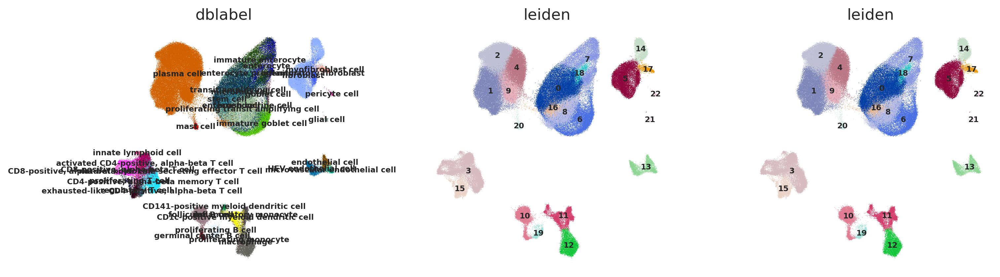

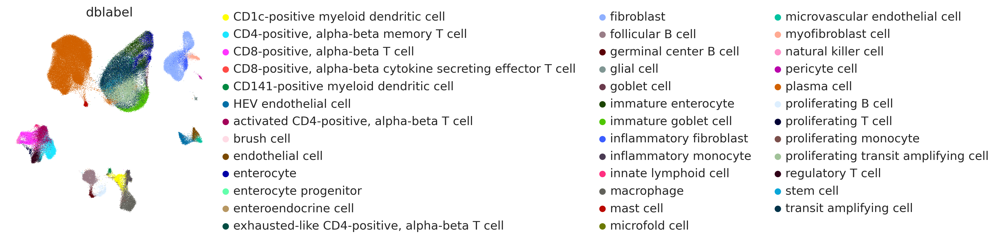

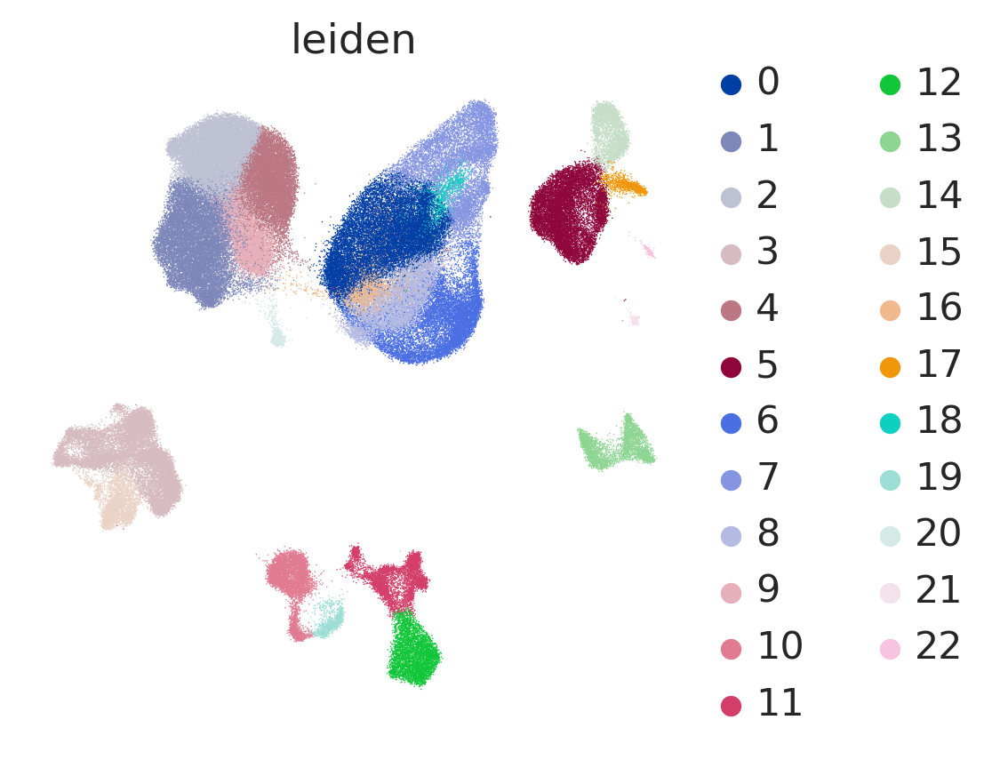

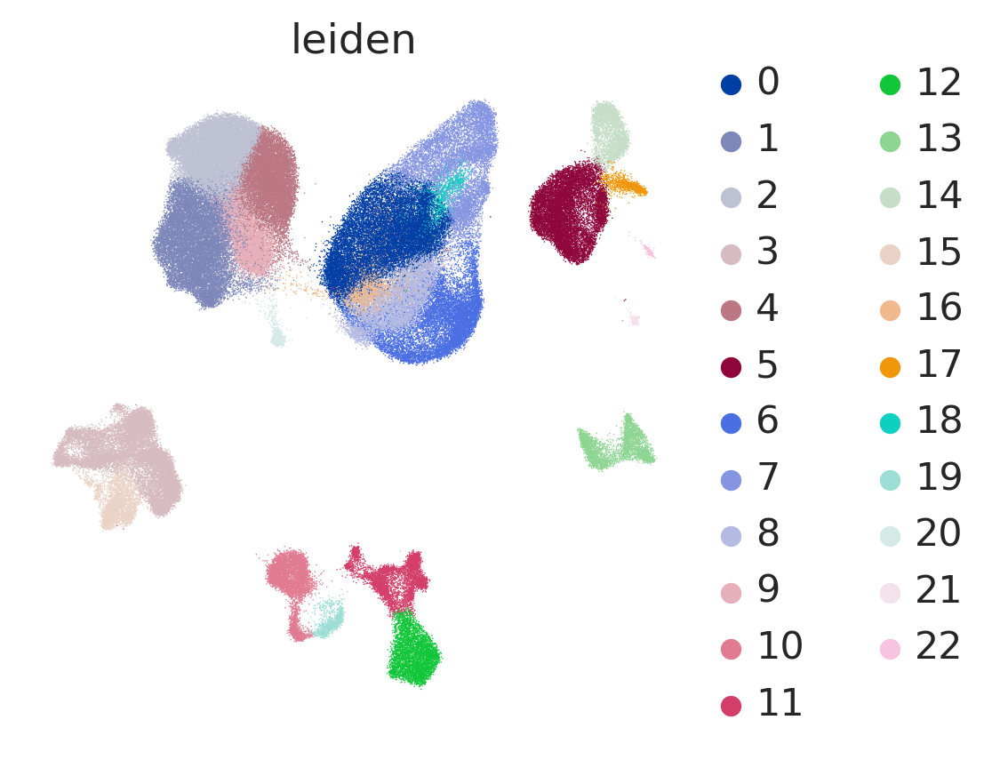

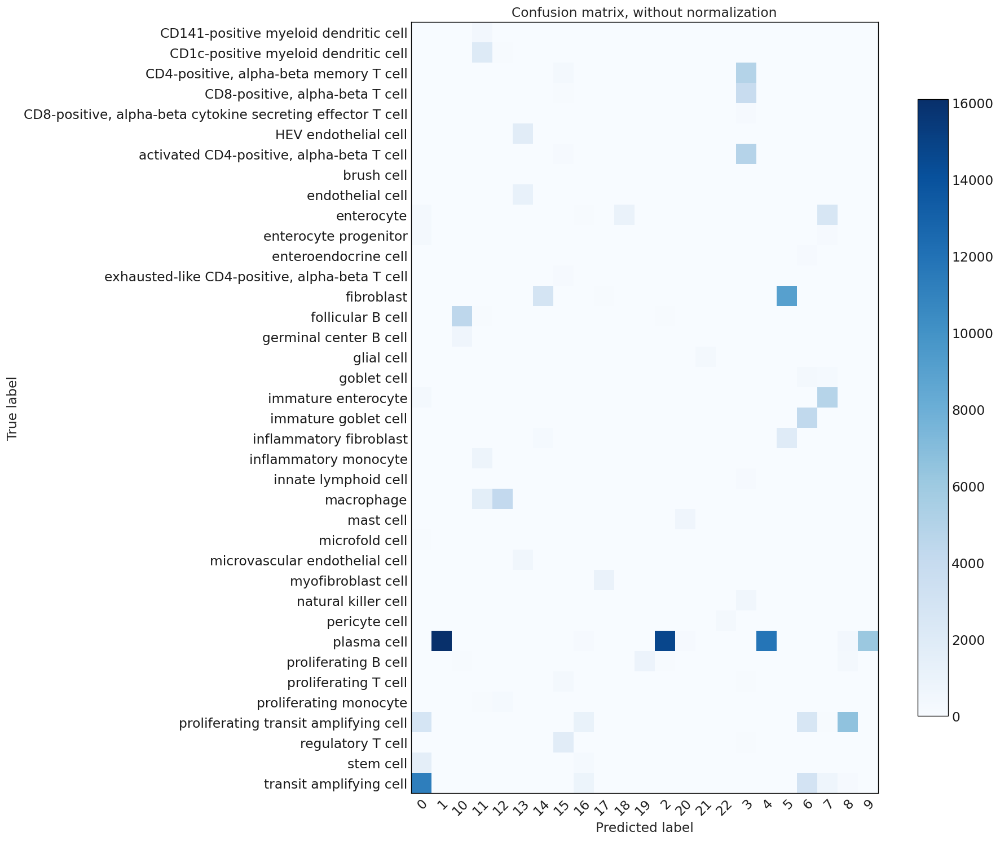

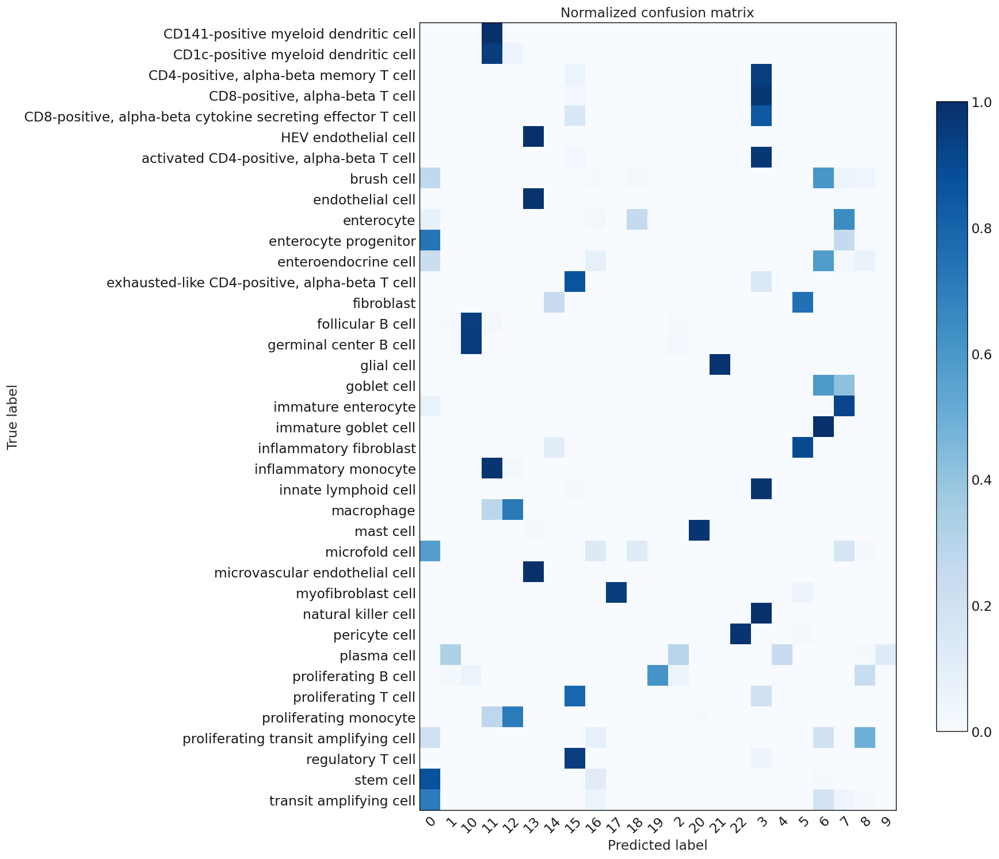

In [48]:
bc.tl.report(adata_pred=adata_std, celltype='dblabel', method='hvg_selection_before_regress_out', analysis_name='standard_workflow_besca2_0',
                        test_dataset='adata_std', name_prediction='leiden', name_report='compare_dblabel', use_raw=False,
                        remove_nonshared=False, clustering='leiden', asymmetric_matrix=True, delimiter='\t', verbose=True)

acc: 0.0
f1: 0.0
ami: 0.71
ari: -0.75
silhouette Cluster: 0.13
silhouette leiden: 0.27
pair confusion matrix:              0           1
0  18783928526   629248698
1   1997890318  1008454550


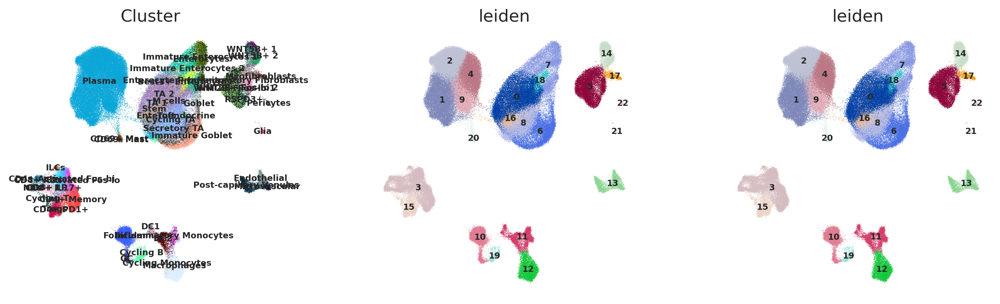

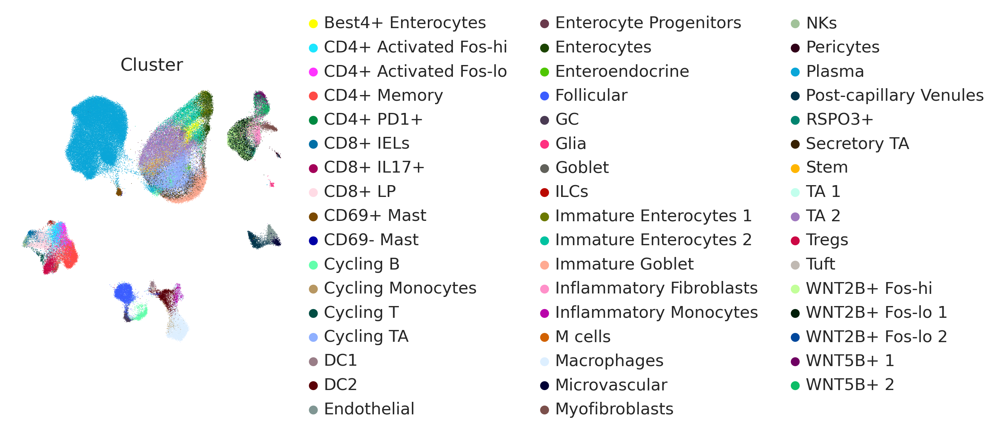

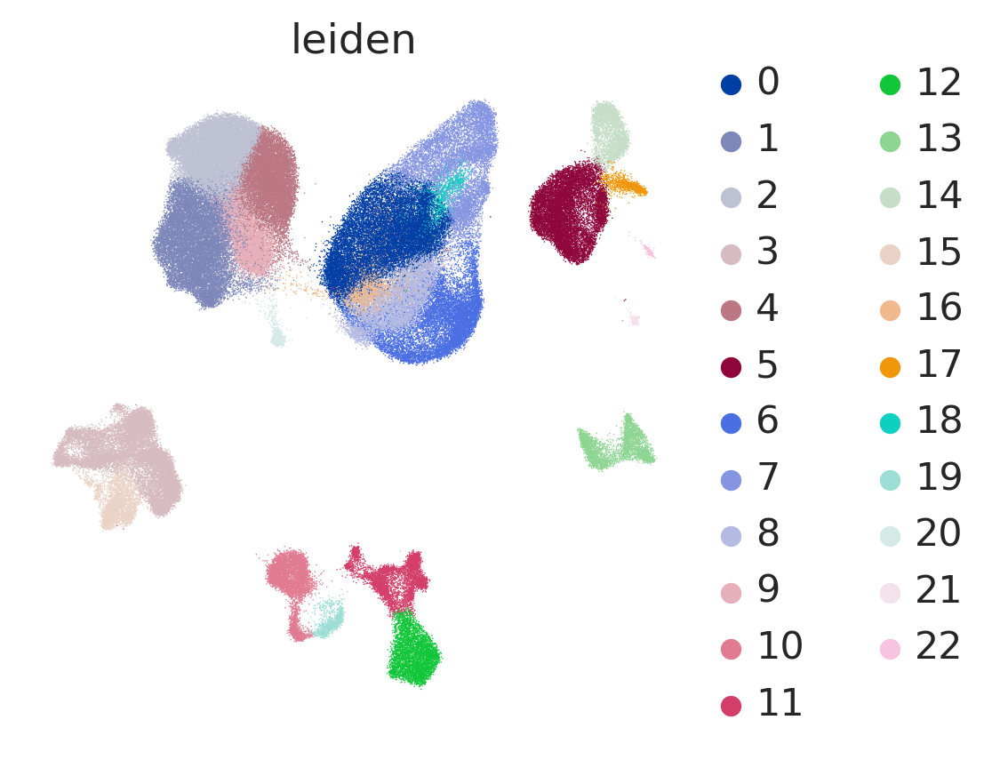

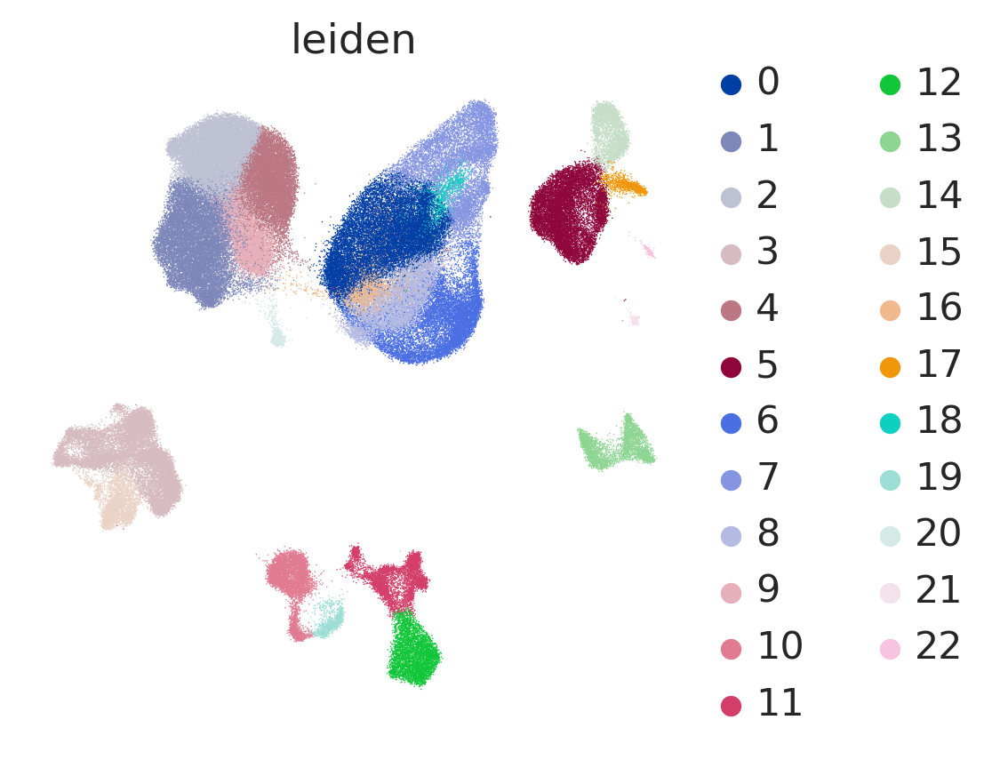

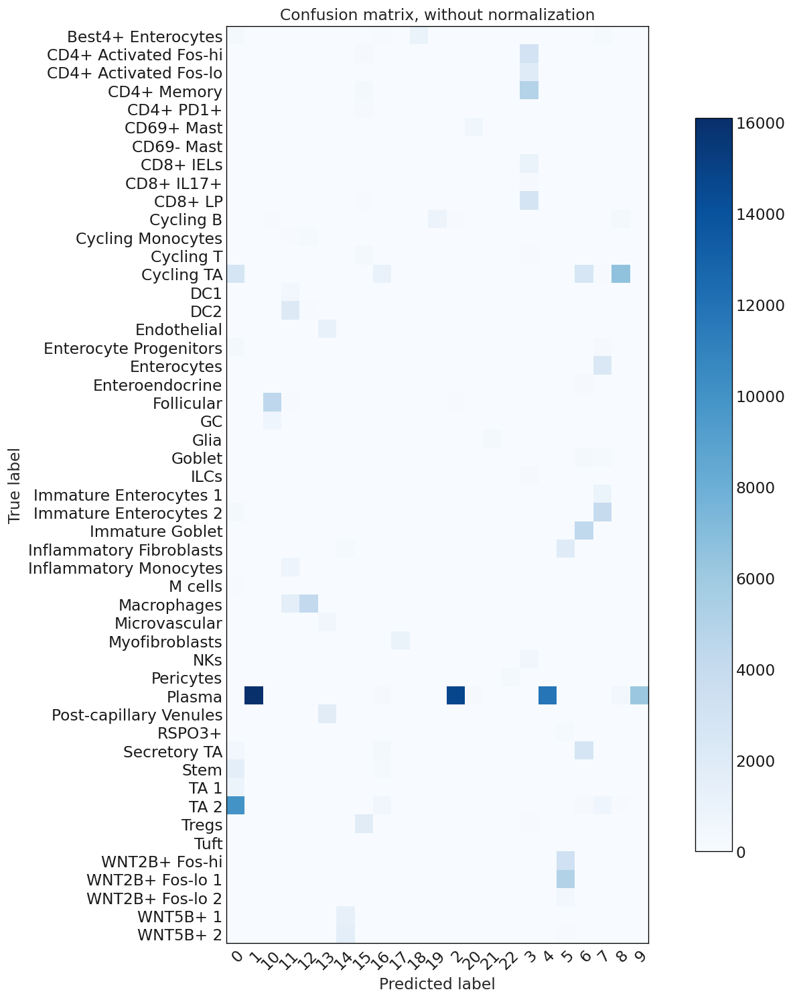

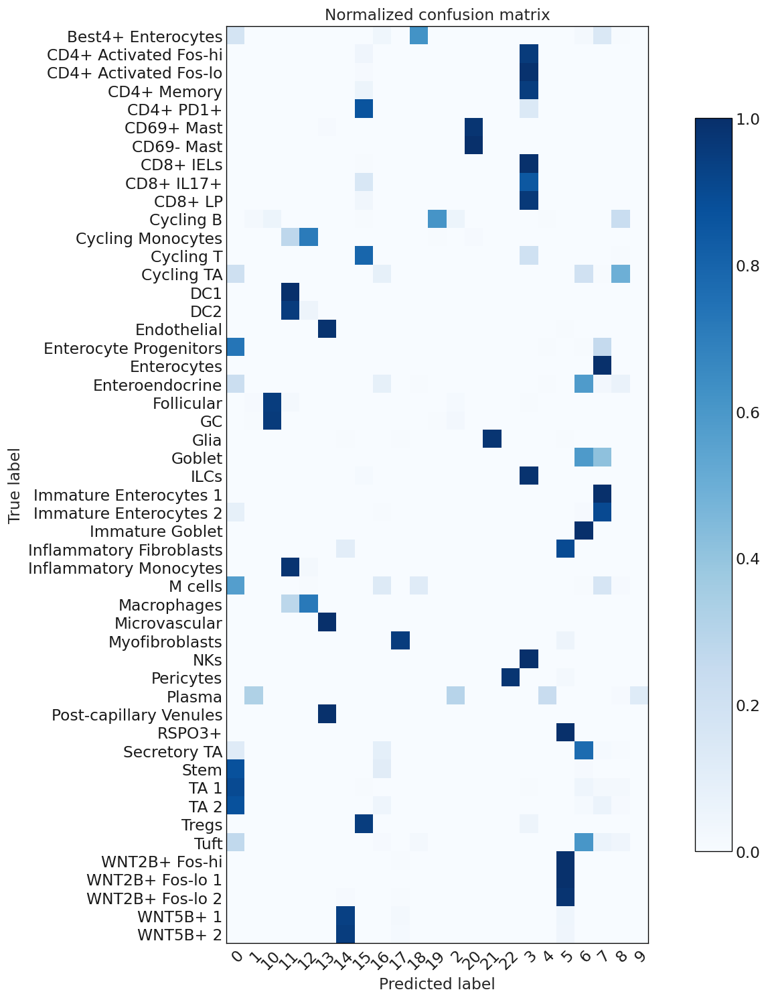

In [49]:
bc.tl.report(adata_pred=adata_std, celltype='Cluster', method='hvg_selection_before_regress_out', analysis_name='standard_workflow_besca2_0',
                        test_dataset='adata_std', name_prediction='leiden', name_report='compare_Cluster', use_raw=False,
                        remove_nonshared=False, clustering='leiden', asymmetric_matrix=True, delimiter='\t', verbose=True)